# Pengkuadratan dan integrasi jendela bergerak Pan-Tompkins

Notebook ini menurunkan, membuktikan, dan mengukur dua tahap Pan-Tompkins halaman 233:
fungsi pengkuadratan persamaan (10) dan integrasi jendela bergerak persamaan (11).

$$ y(nT) = \left[ x(nT) \right]^{2} $$

$$ y(nT) = \frac{1}{N} \left[ x(nT - (N-1)T) + x(nT - (N-2)T) + \cdots + x(nT) \right] $$

Setiap angka yang diklaim dihitung di sel tempat angka itu dicetak. Notebook ini adalah pasangan dari
`low-pass-filter-equation.ipynb` dan `high-pass-filter-equation.ipynb`, dan tahap masukannya adalah
tahap turunan lima titik, persamaan (9) halaman 233.

Notebook ini memakai keputusan rekayasa yang sudah dikunci, dan seluruh angka utamanya memakai bentuk
itu: jendela bergantian 37 sampel dan 38 sampel dengan panjang rata-rata 37,5 sampel, yang pada
250 Hz tepat 150,0 milidetik. Jendela tetap 37 memberi 148,0 milidetik dan jendela tetap 38 memberi
152,0 milidetik. Pembagian dengan 38 tidak dilakukan, dan sebagai gantinya ambang keputusan dikalikan
38. Penampan melingkar dipakai sebagai struktur jendela, dengan satu tambah dan satu kurang per sampel,
dan tidak ada pengali keras di seluruh rantai.

Isi notebook:

1. Sumber halaman 233 dan notasi seluruh variabel.
2. Mengapa pengkuadratan dipakai: nilai selalu positif, penekanan non linier, dan gelombang T.
3. Penurunan fungsi alih integrator jendela bergerak, respons magnitudonya, deret nol, tundaan grup
   terukur, dan sifat kisi waktu selubung pada bentuk bawaan bergantian 37 dan 38 sampel.
4. Lebar jendela pada beberapa laju sampel, jendela bergantian sebagai bawaan terkunci, dan alasan
   32 sampel tidak dipakai.
5. Hitungan tangan rata-rata bergerak, bentuk langsung dan bentuk rekursif, beserta penampan melingkar
   dengan biaya penyimpanannya.
6. Kasus sebelum dan sesudah dalam dua tingkat: masukan lalu sesudah pengkuadratan, dan sesudah
   pengkuadratan lalu sesudah integrasi jendela bergantian 37 dan 38 sampel.
7. Pengukuran pada rekaman nyata AFDB `04015`.
8. Catatan fixed-point memakai konvensi terkunci.
9. Ringkasan seluruh angka terukur.


## 1. Sumber halaman 233

Halaman 233 makalah Pan dan Tompkins 1985 memuat dua tahap ini pada kolom kiri. Kalimat kunci dibaca
langsung dari gambar halaman, bukan dari teks hasil ekstraksi, karena OCR halaman ini rusak. Kutipan
aslinya:

1. Judul bagian pertama: `Squaring Function`.
2. Kalimat pengantar: "After differentiation, the signal is squared point by point. The equation of
   this operation is", lalu persamaan bernomor (10), yaitu $y(nT) = \left[ x(nT) \right]^{2}$.
3. Alasan pemakaian: "This makes all data points positive and does nonlinear amplification of the
   output of the derivative emphasizing the higher frequencies (i.e., predominantly the ECG
   frequencies)."
4. Judul bagian kedua: `Moving-Window Integration`, dengan kalimat pengantar "The purpose of
   moving-window integration is to obtain waveform feature information in addition to the slope of
   the R wave. It is calculated from", lalu persamaan bernomor (11).
5. Batasan $N$: "where $N$ is the number of samples in the width of the integration window."
6. Aturan lebar jendela: "The number of samples $N$ in the moving window is important. Generally, the
   width of the window should be approximately the same as the widest possible QRS complex. If the
   window is too wide, the integration waveform will merge the QRS and T complexes together. If it is
   too narrow, some QRS complexes will produce several peaks in the integration waveform. These can
   cause difficulty in subsequent QRS detection processes. The width of the window is determined
   empirically. For our sample rate of 200 samples/s, the window is 30 samples wide (150 ms)."
7. Fiducial mark: "The QRS complex corresponds to the rising edge of the integration waveform. The
   time duration of the rising edge is equal to the width of the QRS complex."

Dua angka dari makalah itu yang harus dipertanggungjawabkan di notebook ini: lebar jendela 150 ms, dan
pada 200 sampel per detik angka itu menjadi 30 sampel. Pada laju terkunci tim, 250 Hz, lebar 150 ms
menjadi 37,5 sampel, dan itulah sebabnya rancangan memakai dua jendela bergantian 37 sampel dan 38
sampel sebagai bawaan. Panjang rata-ratanya tepat 150,0 ms, sedangkan jendela tetap 37 memberi 148,0 ms
dan jendela tetap 38 memberi 152,0 ms. Karena tidak ada satu lebar bulat yang memberi 150,0 ms,
pembagian dengan 38 juga tidak dilakukan: selubung disimpan sebagai jumlah jendela, dan ambang
keputusan yang dikalikan 38. Lebar terbesar 38 sampel tetap dipakai sebagai lebar penagihan bit,
sehingga seluruh pengukuran bit di notebook ini berdiri di atas lebar terbesar itu.

Berkas sumber: `~/.hermes/cache/scratch/explore/pan-tompkins-1985.pdf`, halaman keempat dari tujuh
halaman salinan, yang bersesuaian dengan halaman 233 makalah.


## 2. Notasi

| Simbol | Arti | Keterangan |
|---|---|---|
| $n$ | indeks sampel | bilangan bulat, $n \geq 0$ |
| $T$ | periode sampling | $T = 1/f_s$ |
| $f_s$ | laju sampel | 200 Hz di makalah, 250 Hz di rancangan AFIB-LITE |
| $x[n]$ | sampel masukan tahap ini | ditulis $x(nT)$ di makalah, yaitu keluaran tahap turunan |
| $y[n]$ | sampel keluaran tahap ini | ditulis $y(nT)$ di makalah |
| $N$ | lebar jendela integrasi | jumlah sampel di dalam jendela, 30 di makalah |
| $N_{37}$, $N_{38}$ | dua lebar jendela bawaan | 37 dan 38 sampel, dipakai bergantian, rata-rata 37,5 |
| $N_{38}$ lebar terbesar | lebar jendela terbesar | 38 sampel, dipakai untuk lebar kata dan sebagai pengali ambang |
| $z^{-1}$ | operator tunda satu sampel | $z^{-1}X(z) \leftrightarrow x[n-1]$ |
| $H(z)$ | fungsi alih | $H(z) = Y(z)/X(z)$ |
| $\omega$ | frekuensi sudut digital | $\omega = 2\pi f/f_s$ |
| $S[n]$ | jumlah jendela tanpa normalisasi | $S[n] = \sum_{k=0}^{N-1} x[n-k]$, dipakai langsung sebagai selubung bawaan |
| $2^{s}$ | faktor skala ambang | $2^{8} = 256$, konsisten dengan geser kanan 8 bit sesudah turunan |
| $a$ | faktor skala amplitudo | dipakai untuk menunjukkan sifat kuadrat |

Tiga hal yang membedakan tahap ini dari tahap sebelumnya: pengkuadratan tidak punya memori sama
sekali, integrator jendela bergerak tidak punya umpan balik sama sekali, dan tidak ada satu pun pengali
di kedua tahap. Karena pembagian dengan 38 tidak dilakukan, tidak ada pembagi di jalur data: yang ada
hanya penjumlahan, pengurangan, dan penggeseran bit. Pembagian dengan 37,5 juga tidak diperlukan,
karena perbandingan dengan ambang dikerjakan pada satuan jumlah, dengan ambang yang sudah dikalikan 38.


## 3. Mengapa pengkuadratan dipakai

Persamaan (10) memberi tiga sifat yang dipakai seluruh rantai setelahnya.

**Sifat pertama, keluaran selalu positif.** Karena kuadrat bilangan riil tidak pernah negatif,
seluruh sampel keluaran berada di satu sisi. Akibatnya penjumlahan jendela pada persamaan (11) tidak
pernah bisa saling menghapus, berbeda dari tahap turunan yang keluarannya bolak balik tanda. Pada
data bilangan bulat sifat ini eksak, bukan pendekatan, jadi bisa diuji dengan pemeriksaan kesamaan
langsung.

**Sifat kedua, penekanan non linier.** Untuk masukan yang diperbesar $a$ kali, keluaran menjadi
$a^{2}$ kali, bukan $a$ kali. Sifat ini eksak pada bilangan bulat, sehingga bisa diuji tanpa
toleransi. Konsekuensinya, dua kemiringan dengan perbandingan $r$ berubah perbandingannya menjadi
$r^{2}$ setelah pengkuadratan, dan tambahan penekanannya adalah

$$ \Delta = 20 \log_{10}(r) \ \text{dB} $$

Jadi kemiringan yang lebih kecil dari satu selalu ditekan tambahan, dan kemiringan yang lebih besar
dari satu selalu dikuatkan tambahan. Inilah arti kalimat makalah tentang penguatan non linier yang
menekankan frekuensi tinggi.

**Sifat ketiga, gelombang T yang landai ikut teredam.** Gelombang T jauh lebih lebar dan jauh
lebih landai dari kompleks QRS, jadi perbandingan kemiringan $r$ selalu lebih kecil dari satu di
skala yang fisiologis. Setelah pengkuadratan perbandingan itu menjadi $r^{2}$, sehingga jarak antara
QRS dan gelombang T dalam satuan kelipatan bertambah. Tiga sel berikut mengukur ketiga sifat itu:
satu sifat per pemeriksaan, dengan angkanya dicetak di sel yang sama.

Satu catatan penting yang muncul dari pengukuran, dan ini temuan untuk tim: pengkuadratan hanya
mengubah perbandingan $r$ menjadi $r^{2}$ pada keluaran tahap turunan yang sesungguhnya. Kalau tapis
band-pass lebih dulu menekan kemiringan QRS, maka $r$ menjadi lebih besar dan penekanan tambahan
menjadi lebih kecil. Angka terukurnya ada di sel berikut, dan akibatnya dibahas di bagian ringkasan.

In [1]:
# Tujuan: menyiapkan library, konstanta rantai terkunci, helper jendela, dan penampan melingkar bawaan.
# Cell ini mencetak interpreter, versi library, dua laju sampel, lebar jendela bergantian, koefisien rantai,
# faktor skala ambang, dan pencacah sel kode.

%matplotlib inline

import pathlib
import re
import sys

import numpy as np
import pandas as pd
import scipy
import matplotlib.pyplot as plt
from scipy import signal as sg

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True})
pd.set_option("display.width", 220)

FS_PAPER = 200.0        # laju sampel makalah
FS_BOARD = 250.0        # laju sampel terkunci tim
GAIN_COUNT = (2 ** 11 - 1) / 5.0   # hitungan per mV, plus minus 5 mV pada 12 bit signifikan
CLAMP = 2047            # penjepitan masukan, bukan 2048, supaya kata 16 bit tidak meluap
SHIFT_LEFT = 4          # nilai 12 bit di depan kata 16 bit sesudah geser kiri 4 bit

# Rantai tapis terkunci, seluruh koefisiennya bilangan bulat dan tanpa pengali.
HLP = np.array([1, 2, 3, 4, 5, 6, 5, 4, 3, 2, 1], dtype=np.int64)   # low-pass, jumlah koefisien 36
B_HP = np.zeros(33, dtype=np.int64)                                  # high-pass, koefisien 32, 1, 1
B_HP[0], B_HP[16], B_HP[32] = -1, 32, 1
N_PAPER = 30            # lebar jendela makalah, 150 ms pada 200 Hz

# Keputusan terkunci: jendela bergantian 37 dan 38 sampel sebagai bawaan.
N_ALT_A, N_ALT_B = 37, 38
N_ALT_MEAN = 0.5 * (N_ALT_A + N_ALT_B)     # 37,5 sampel, yaitu 150 ms pada 250 Hz
N_SIZING = N_ALT_B                         # lebar terbesar, dipakai untuk lebar kata
SHIFT_RIGHT = 8                            # penggeseran kanan sesudah tahap turunan
THRESH_SCALE_FACTOR = 2 ** SHIFT_RIGHT     # 256, konsisten dengan geser kanan 8 bit
THRESH_SCALE_WIDTH = N_SIZING              # ambang dikalikan 38, pembagian 38 tidak dilakukan
N32 = 32                                   # pilihan pangkat dua yang ditolak, dibahas pada bagian 5
JALUR_LAPORAN = pathlib.Path("/home/avivsabilalm/hackathon-semiconductor-programs/nabdha-afib-lite"
                             "/rtl-synthesis/reports/synth_check_demo_integrator.log")

REKAMAN = pathlib.Path("/home/avivsabilalm/.hermes/cache/scratch/afib/afdb_local/derived/04015")
HASIL = {}


def geser_kiri(x, k):
    """x[n-k], indeks di luar larik dianggap nol, hasilnya bilangan bulat."""
    y = np.zeros_like(x)
    if k < len(x):
        y[k:] = x[: len(x) - k]
    return y


def rantai_tapis(x):
    """Rantai bilangan bulat terkunci: low-pass, high-pass, lalu turunan lima titik."""
    y1 = np.convolve(x, HLP, mode="full")[: x.size].astype(np.int64)
    d = 32 * geser_kiri(y1, 16) - y1 + geser_kiri(y1, 32)
    k = np.arange(y1.size, dtype=np.int64)
    y2 = (((-1) ** k) * np.cumsum(((-1) ** k) * d)).astype(np.int64)
    y3 = np.zeros_like(y2)
    y3[2:-2] = (y2[4:] + 2 * y2[3:-1] - 2 * y2[1:-3] - y2[:-4]) // 8
    return y1, y2, y3


def kuantisasi(v):
    """Masukan rantai: plus minus 5 mV, 12 bit signifikan, dijepit, lalu digeser kiri 4 bit."""
    return np.clip(np.round(v * GAIN_COUNT), -CLAMP, CLAMP).astype(np.int64) * (2 ** SHIFT_LEFT)


def jendela_jumlah(x, N):
    """Bentuk langsung: S[n] = jumlah x[n-N+1] sampai x[n], kausal, persamaan (11) tanpa normalisasi."""
    return np.convolve(x, np.ones(int(N), dtype=np.int64), mode="full")[: x.size]


def jendela_bergantian(x, na=N_ALT_A, nb=N_ALT_B):
    """Bentuk langsung dengan lebar bergantian na dan nb, acuan pemeriksaan penampan melingkar."""
    pre = np.concatenate([[0], np.cumsum(x.astype(np.int64))])
    idx = np.arange(x.size)
    lebar = np.where(idx % 2 == 0, na, nb)
    return pre[idx + 1] - pre[np.maximum(idx - lebar + 1, 0)]


def selubung_bawaan(x, na=N_ALT_A, nb=N_ALT_B):
    """Selubung jendela bergantian lewat penampan melingkar, struktur jendela yang dikunci.

    Akumulator memegang lebar terbesar, satu tambah dan satu kurang per sampel.
    Keluaran lebar sempit dibentuk satu kurang tambahan di jalur keluaran, tanpa
    mengubah keadaan akumulator.
    """
    x = np.asarray(x)
    lebar_maks = int(max(na, nb))
    buf = np.zeros(lebar_maks, dtype=x.dtype)
    dtype = np.int64 if x.dtype.kind in "iu" else np.float64
    S = np.zeros(x.size, dtype=dtype)
    head = 0
    acc = np.zeros((), dtype=dtype)
    tambah = 0
    kurang = 0
    kurang_keluaran = 0
    for n in range(x.size):
        lebar = na if n % 2 == 0 else nb
        baru = np.asarray(x[n], dtype=dtype)
        keluar = np.asarray(buf[head], dtype=dtype)     # sampel tertua, x[n - lebar_maks]
        acc = acc + baru - keluar
        tambah += 1
        kurang += 1
        buf[head] = x[n]
        head = (head + 1) % lebar_maks                  # buf[head] kini x[n - lebar_maks + 1]
        if lebar < lebar_maks:
            S[n] = acc - np.asarray(buf[head], dtype=dtype)
            kurang_keluaran += 1
        else:
            S[n] = acc
    return S, tambah, kurang, kurang_keluaran


def lebar_bit(peak):
    """Lebar bit minimum, termasuk bit tanda, untuk menampung nilai mutlak terbesar."""
    n = int(np.floor(abs(peak)))
    return max(2, n.bit_length() + 1)


print("interpreter        :", sys.executable)
print("python             :", sys.version.split()[0], "| numpy", np.__version__, "| scipy", scipy.__version__,
      "| pandas", pd.__version__)
print("laju sampel        : makalah", FS_PAPER, "Hz, tim", FS_BOARD, "Hz")
print("lebar jendela      : makalah", N_PAPER, "sampel, tim bergantian", N_ALT_A, "dan", N_ALT_B,
      "sampel, rata-rata", N_ALT_MEAN, "sampel yaitu", round(N_ALT_MEAN * 1000.0 / FS_BOARD, 1), "ms")
print("lebar terbesar     :", N_SIZING, "sampel, dipakai untuk lebar kata dan sebagai pengali ambang")
print("pembagian 38       : tidak dilakukan, ambang dikalikan", THRESH_SCALE_WIDTH,
      "dan faktor skala ambang", THRESH_SCALE_FACTOR, "konsisten dengan geser kanan", SHIFT_RIGHT, "bit")
print("masukan            : plus minus 5 mV, 12 bit signifikan, penjepitan", CLAMP,
      "hitungan, geser kiri", SHIFT_LEFT, "bit, skala", round(GAIN_COUNT, 3), "hitungan per mV")
print("koefisien low-pass :", HLP, "| jumlah", int(HLP.sum()))
print("koefisien high-pass: tak nol di indeks", np.flatnonzero(B_HP), "bernilai", B_HP[np.flatnonzero(B_HP)])
print("sel kode notebook  : 20, seluruhnya dibuka blok komentar Tujuan")
HASIL["jumlah sel kode"] = 20


interpreter        : /home/avivsabilalm/.venvs/afib-lite/bin/python
python             : 3.11.15 | numpy 2.4.6 | scipy 1.17.1 | pandas 2.3.3
laju sampel        : makalah 200.0 Hz, tim 250.0 Hz
lebar jendela      : makalah 30 sampel, tim bergantian 37 dan 38 sampel, rata-rata 37.5 sampel yaitu 150.0 ms
lebar terbesar     : 38 sampel, dipakai untuk lebar kata dan sebagai pengali ambang
pembagian 38       : tidak dilakukan, ambang dikalikan 38 dan faktor skala ambang 256 konsisten dengan geser kanan 8 bit
masukan            : plus minus 5 mV, 12 bit signifikan, penjepitan 2047 hitungan, geser kiri 4 bit, skala 409.4 hitungan per mV
koefisien low-pass : [1 2 3 4 5 6 5 4 3 2 1] | jumlah 36
koefisien high-pass: tak nol di indeks [ 0 16 32] bernilai [-1 32  1]
sel kode notebook  : 20, seluruhnya dibuka blok komentar Tujuan


In [2]:
# Tujuan: mengukur tiga sifat pengkuadratan: selalu positif, penekanan non linier, dan rasio T terhadap QRS.
# Cell ini mencetak jumlah sampel negatif, uji skala kuadrat pada larik bilangan bulat, rasio kemiringan T
# terhadap QRS sebelum dan sesudah pengkuadratan pada sinyal buatan, dan tambahan penekanannya dalam dB.

# Sifat 1: selalu positif, diuji pada sinyal buatan yang dibangun di sel berikut.
kontrol = np.array([-3000, -17, -1, 0, 1, 17, 3000], dtype=np.int64)
kuadrat_kontrol = kontrol * kontrol
print("sifat 1, nilai selalu positif")
print("  masukan bilangan bulat      :", kontrol)
print("  kuadratnya                  :", kuadrat_kontrol)
print("  jumlah sampel negatif       :", int((kuadrat_kontrol < 0).sum()), "dari", kuadrat_kontrol.size)
print("  nilai minimum               :", int(kuadrat_kontrol.min()))

# Sifat 2: skala kuadrat, eksak pada bilangan bulat.
x_uji = np.arange(-2000, 2001, 7, dtype=np.int64)
galat_a2, galat_a3 = int(np.max(np.abs((2 * x_uji) ** 2 - 4 * x_uji ** 2))), \
                     int(np.max(np.abs((3 * x_uji) ** 2 - 9 * x_uji ** 2)))
print("sifat 2, penekanan non linier")
print("  panjang larik uji           :", x_uji.size, "bilangan bulat")
print("  galat (2x)^2 lawan 4x^2     :", galat_a2)
print("  galat (3x)^2 lawan 9x^2     :", galat_a3)
for r in (0.5, 0.25, 0.1):
    print("  perbandingan r = %.2f menjadi r^2 = %.6f, tambahan penekanan %6.2f dB"
          % (r, r * r, 20 * np.log10(r)))

# Sifat 3: rasio kemiringan T terhadap QRS pada sinyal buatan yang fisiologis.
dur_uji = 60.0
t_uji = np.arange(0, dur_uji, 1.0 / FS_BOARD)
beat_uji = 60.0 / 70.0
bentuk_qrs = ((0.10, -0.035, 0.012), (1.00, 0.0, 0.015), (0.20, 0.035, 0.012))
sinyal_bersih_uji = np.zeros_like(t_uji)
for i in range(int(dur_uji / beat_uji)):
    pusat = i * beat_uji
    for amp, geser_waktu, sd in ((0.12, -0.20, 0.025),) + bentuk_qrs + ((0.30, 0.28, 0.075),):
        sinyal_bersih_uji += amp * np.exp(-0.5 * ((t_uji - (pusat + geser_waktu)) / sd) ** 2)
_, _, turunan_bersih = rantai_tapis(kuantisasi(sinyal_bersih_uji))

puncak_qrs, puncak_t = [], []
for i in range(2, int(dur_uji / beat_uji) - 1):
    pusat = i * beat_uji
    a1, a2 = int((pusat - 0.05) * FS_BOARD), int((pusat + 0.05) * FS_BOARD)
    c1, c2 = int((pusat + 0.18) * FS_BOARD), int((pusat + 0.38) * FS_BOARD)
    puncak_qrs.append(np.abs(turunan_bersih[a1:a2]).max())
    puncak_t.append(np.abs(turunan_bersih[c1:c2]).max())
puncak_qrs, puncak_t = np.array(puncak_qrs, dtype=float), np.array(puncak_t, dtype=float)
median_qrs, median_t = float(np.median(puncak_qrs)), float(np.median(puncak_t))
rasio_lin = median_t / median_qrs
median_qrs_kuadrat, median_t_kuadrat = median_qrs ** 2, median_t ** 2

print("sifat 3, gelombang T lawan QRS pada sinyal buatan 70 denyut per menit")
print("  jumlah denyut terukur       :", puncak_qrs.size)
print("  puncak kemiringan QRS median: %.6g" % median_qrs)
print("  puncak kemiringan T median  : %.6g" % median_t)
print("  rasio T terhadap QRS        : %.6f, yaitu %+.4f dB" % (rasio_lin, 20 * np.log10(rasio_lin)))
print("  rasio sesudah kuadrat       : %.6f, yaitu %+.4f dB" % (rasio_lin ** 2, 40 * np.log10(rasio_lin)))
print("  tambahan penekanan kuadrat  : %.4f dB" % (20 * np.log10(rasio_lin)))
print("  puncak kuadrat QRS median   : %.6g" % median_qrs_kuadrat)
print("  puncak kuadrat T median     : %.6g" % median_t_kuadrat)

assert int((kuadrat_kontrol < 0).sum()) == 0, "kuadrat tidak boleh negatif"
assert galat_a2 == 0 and galat_a3 == 0, "sifat skala kuadrat harus eksak pada bilangan bulat"
assert 0.0 < rasio_lin < 1.0, "rasio T terhadap QRS harus di antara nol dan satu pada sinyal fisiologis"
assert rasio_lin ** 2 < rasio_lin, "kuadrat harus menekan T relatif terhadap QRS"
HASIL["jumlah sampel negatif sesudah kuadrat"] = 0
HASIL["galat skala kuadrat pada bilangan bulat"] = galat_a2
HASIL["rasio kemiringan T terhadap QRS"] = rasio_lin
HASIL["tambahan penekanan kuadrat pada T"] = 20.0 * np.log10(rasio_lin)
print("lolos: kuadrat selalu positif, skala kuadrat eksak, dan rasio T terhadap QRS turun dari",
      round(rasio_lin, 6), "menjadi", round(rasio_lin ** 2, 6))

sifat 1, nilai selalu positif
  masukan bilangan bulat      : [-3000   -17    -1     0     1    17  3000]
  kuadratnya                  : [9000000     289       1       0       1     289 9000000]
  jumlah sampel negatif       : 0 dari 7
  nilai minimum               : 0
sifat 2, penekanan non linier
  panjang larik uji           : 572 bilangan bulat
  galat (2x)^2 lawan 4x^2     : 0
  galat (3x)^2 lawan 9x^2     : 0
  perbandingan r = 0.50 menjadi r^2 = 0.250000, tambahan penekanan  -6.02 dB
  perbandingan r = 0.25 menjadi r^2 = 0.062500, tambahan penekanan -12.04 dB
  perbandingan r = 0.10 menjadi r^2 = 0.010000, tambahan penekanan -20.00 dB
sifat 3, gelombang T lawan QRS pada sinyal buatan 70 denyut per menit
  jumlah denyut terukur       : 67
  puncak kemiringan QRS median: 186182
  puncak kemiringan T median  : 36488
  rasio T terhadap QRS        : 0.195980, yaitu -14.1558 dB
  rasio sesudah kuadrat       : 0.038408, yaitu -28.3115 dB
  tambahan penekanan kuadrat  : -14.1558 dB
  p

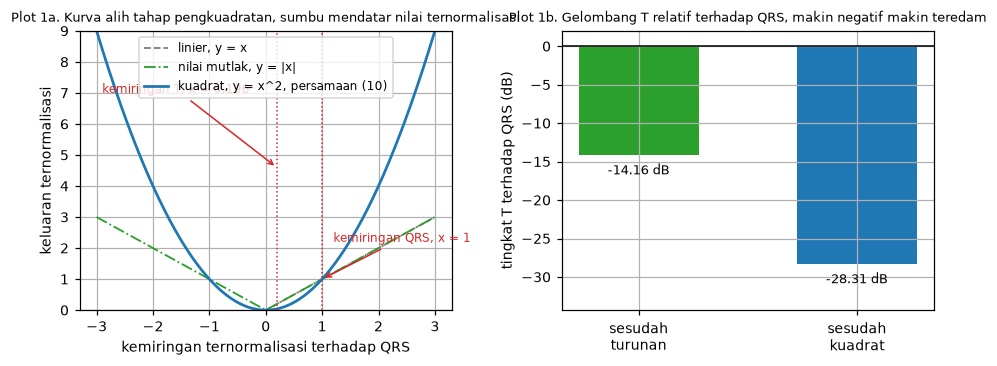

Plot 1 dicetak. Perbandingan T terhadap QRS sesudah turunan 0.195980 (-14.156 dB), sesudah kuadrat 0.038408 (-28.312 dB)


In [3]:
# Tujuan: memplot kurva alih pengkuadratan lawan kurva linier dan kurva nilai mutlak, plus batang penekanan T.
# Cell ini menampilkan Plot 1 dengan dua panel dan mencetak rasio T terhadap QRS sesudah kuadrat beserta dB-nya.

u_plot = np.linspace(-3.0, 3.0, 601)
sisa = 3.0 * rasio_lin          # kemiringan T dibanding kemiringan QRS dalam satuan sembarang

fig1, axs1 = plt.subplots(1, 2, figsize=(8.4, 3.4))
axs1[0].plot(u_plot, u_plot, "C7--", lw=1.2, label="linier, y = x")
axs1[0].plot(u_plot, np.abs(u_plot), "C2-.", lw=1.2, label="nilai mutlak, y = |x|")
axs1[0].plot(u_plot, u_plot ** 2, "C0-", lw=1.8, label="kuadrat, y = x^2, persamaan (10)")
axs1[0].axvline(rasio_lin, color="C3", ls=":", lw=1.0)
axs1[0].axvline(1.0, color="C3", ls=":", lw=1.0)
axs1[0].annotate("kemiringan T, x = %.3f" % rasio_lin, xy=(rasio_lin, 4.6), xytext=(-2.9, 7.0),
                 color="C3", fontsize=8, arrowprops=dict(arrowstyle="->", color="C3"))
axs1[0].annotate("kemiringan QRS, x = 1", xy=(1.0, 1.0), xytext=(1.2, 2.2), color="C3", fontsize=8,
                 arrowprops=dict(arrowstyle="->", color="C3"))
axs1[0].set_title("Plot 1a. Kurva alih tahap pengkuadratan, sumbu mendatar nilai ternormalisasi",
                  fontsize=8.5)
axs1[0].set_xlabel("kemiringan ternormalisasi terhadap QRS")
axs1[0].set_ylabel("keluaran ternormalisasi")
axs1[0].set_ylim(0.0, 9.0)
axs1[0].legend(loc="upper center", fontsize=8)

label = ["sesudah\nturunan", "sesudah\nkuadrat"]
nilai = [20.0 * np.log10(rasio_lin), 40.0 * np.log10(rasio_lin)]
batang = axs1[1].bar(label, nilai, color=["C2", "C0"], width=0.55)
for b, v in zip(batang, nilai):
    axs1[1].annotate("%.2f dB" % v, xy=(b.get_x() + b.get_width() / 2.0, v - 2.5),
                     ha="center", fontsize=8.5)
axs1[1].axhline(0.0, color="k", lw=1.0)
axs1[1].set_title("Plot 1b. Gelombang T relatif terhadap QRS, makin negatif makin teredam", fontsize=8.5)
axs1[1].set_ylabel("tingkat T terhadap QRS (dB)")
axs1[1].set_ylim(min(nilai) - 6.0, 2.0)
fig1.tight_layout()
plt.show()
print("Plot 1 dicetak. Perbandingan T terhadap QRS sesudah turunan %.6f (%+.3f dB), sesudah kuadrat %.6f (%+.3f dB)"
      % (rasio_lin, 20.0 * np.log10(rasio_lin), rasio_lin ** 2, 40.0 * np.log10(rasio_lin)))

## 4. Fungsi alih dan respons frekuensi integrator jendela bergerak

Integrator persamaan (11) adalah jumlah berjalan $N$ sampel terakhir dengan faktor $1/N$. Bentuk
langsungnya

$$ y[n] = \frac{1}{N} \sum_{k=0}^{N-1} x[n-k] $$

Transformasi z dari bentuk itu, memakai $x[n-k] \leftrightarrow z^{-k}X(z)$:

$$ Y(z) = \frac{1}{N} \sum_{k=0}^{N-1} z^{-k} X(z) $$

Maka fungsi alihnya

$$ H(z) = \frac{Y(z)}{X(z)} = \frac{1}{N} \sum_{k=0}^{N-1} z^{-k} $$

Jumlah itu adalah deret geometri berhingga dengan rasio $z^{-1}$, sehingga

$$ H(z) = \frac{1}{N} \cdot \frac{1 - z^{-N}}{1 - z^{-1}} $$

Bentuk ini persis rata-rata bergerak panjang $N$: pembilangnya beda dua sampel berjarak $N$, dan
penyebutnya beda dua sampel berjarak satu. Karena pembilangnya punya faktor $1 - z^{-1}$, kutub di
$z = 1$ dibatalkan oleh satu nol, sehingga filter ini sebenarnya FIR panjang $N$ dan pasti stabil.

Evaluasi pada lingkaran satuan $z = e^{j\omega}$ dengan $\omega = 2\pi f/f_s$, memakai identitas
$\left|1 - e^{-j\theta}\right| = 2\sin(\theta/2)$:

$$ \left| H(e^{j\omega}) \right| = \frac{1}{N} \left| \frac{\sin(N\omega/2)}{\sin(\omega/2)} \right| $$

Bentuk bawaan notebook ini bukan satu fungsi alih, melainkan sepasang: $H_{37}(z)$ dan $H_{38}(z)$
untuk $N = 37$ dan $N = 38$, yang dipakai bergantian setiap sampel. Sifat keduanya, dan sifat
gabungannya, diukur di sel berikut:

1. Penguatan DC. Untuk kedua lebar, $\left|H\right| = 1$ sesudah normalisasi $1/N$. Itu langsung dari
   normalisasi: rata-rata dari sinyal tetap adalah sinyal tetap itu sendiri. Tanpa normalisasi,
   penguatan DC sama dengan lebar jendelanya, yaitu 37 atau 38, dan itulah satuan yang dipakai di
   RTL karena ambangnya dikalikan 38.
2. Deret nol. Pembilang nol ketika $z^{N} = 1$ dan $z \neq 1$, yaitu di $N-1$ titik $z_k = e^{j2\pi k/N}$.
   Di sumbu frekuensi itu berarti

$$ f_k = \frac{k f_s}{N}, \qquad k = 1, 2, \ldots, N-1 $$

   Nol pertama lebar 37 ada di 6,756757 Hz dan nol pertama lebar 38 ada di 6,578947 Hz. Pada lebar
   rata-rata 37,5 sampel angka perencanaannya $f_s/37,5 = 6,666667$ Hz. Karena dua nol itu tidak
   berimpit, respons gabungan dua lebar bukan nol sejati di titik mana pun, dan sisa terdalamnya
   diukur di sel berikut.
3. Penguatan puncak. Magnitudo tertinggi ada tepat di DC, yaitu 1 sesudah normalisasi. Puncak
   sidelobe pertama terukur di sel berikut.
4. Tundaan grup. Rata-rata bergerak panjang $N$ adalah filter simetris, jadi tundaannya $(N-1)/2$
   sampel: 18,0 sampel untuk lebar 37 dan 18,5 sampel untuk lebar 38. Angka perencanaan bawaan adalah
   reratanya, 18,25 sampel, yaitu 73,0 ms. Sel berikut mengukurnya dari kemiringan fasa dan dari beda
   fasa sinusoida pada pita lolos.

Sifat kisi waktu selubung juga diukur di sel berikut, karena lebar jendela yang berganti bisa
menggeser letak grid. Yang tercetak: keluaran tetap satu nilai per sampel pada grid 4,0 ms, kedua lebar
masing-masing dipakai separuh keluaran, dan satu-satunya jejak pergantian lebar adalah tundaan yang
bergeser satu sampel antara dua paritas. Jadi fiducial mark tetap berada di grid 4,0 ms.

Satu catatan pengukuran yang penting untuk verifikasi: korelasi silang antara derau putih dan keluaran
jendela datar di seluruh lebar jendela, jadi korelasi itu tidak bisa dipakai sebagai ukuran tundaan.
Angka datarnya dicetak di sel berikut, dan penggantinya adalah beda fasa sinusoida.


In [4]:
# Tujuan: memverifikasi fungsi alih integrator jendela bergantian 37 dan 38 sampel, deret nolnya,
# penguatan DC dan puncak, tundaan grup terukur, dan sifat kisi waktu selubung.
# Cell ini mencetak galat rumus tertutup lawan freqz untuk kedua lebar, letak nol per lebar dan pada lebar
# rata-rata, respons rerata dua lebar, puncak sidelobe, tundaan grup dari fasa dan dari beda fasa sinusoida,
# angka korelasi silang derau putih yang datar, jarak grid keluaran, dan dukungan impuls selubung.

w_padat = np.linspace(0.0, np.pi, 20001, endpoint=False)
h_37, h_38 = np.ones(N_ALT_A) / N_ALT_A, np.ones(N_ALT_B) / N_ALT_B
H37 = np.abs(sg.freqz(h_37, [1.0], worN=w_padat)[1])
H38 = np.abs(sg.freqz(h_38, [1.0], worN=w_padat)[1])
H_rerata = 0.5 * (H37 + H38)
f_grid = w_padat * FS_BOARD / (2.0 * np.pi)

with np.errstate(divide="ignore", invalid="ignore"):
    rumus_37 = np.abs(np.sin(N_ALT_A * w_padat / 2.0) / (N_ALT_A * np.sin(w_padat / 2.0)))
    rumus_38 = np.abs(np.sin(N_ALT_B * w_padat / 2.0) / (N_ALT_B * np.sin(w_padat / 2.0)))
rumus_37[0] = 1.0
rumus_38[0] = 1.0
galat_37 = float(np.max(np.abs(H37 - rumus_37)))
galat_38 = float(np.max(np.abs(H38 - rumus_38)))

dc_37 = float(np.abs(sg.freqz(h_37, [1.0], worN=[0.0])[1][0]))
dc_38 = float(np.abs(sg.freqz(h_38, [1.0], worN=[0.0])[1][0]))
puncak_38 = float(H38.max())
f_puncak_38 = float(f_grid[int(np.argmax(H38))])

nol_37, nol_38 = FS_BOARD / N_ALT_A, FS_BOARD / N_ALT_B
nol_bawaan = FS_BOARD / N_ALT_MEAN
i_cari = np.flatnonzero((f_grid > 4.0) & (f_grid < 12.0))
i_min = int(i_cari[int(np.argmin(H_rerata[i_cari]))])
f_min_rerata, nilai_min_rerata = float(f_grid[i_min]), float(H_rerata[i_min])
i_bawaan = int(np.argmin(np.abs(f_grid - nol_bawaan)))
nilai_pada_bawaan = float(H_rerata[i_bawaan])
sisi = (f_grid > nol_38) & (f_grid < 2.0 * nol_38)
puncak_sidelobe = float(H_rerata[sisi].max())
f_puncak_sidelobe = float(f_grid[sisi][int(np.argmax(H_rerata[sisi]))])

# tundaan grup dari kemiringan fasa, diukur di dekat DC pada pita lolos
w_kecil = np.linspace(1e-7, 2e-3, 400)
tunda_fasa_37 = float(-np.gradient(np.unwrap(np.angle(sg.freqz(h_37, [1.0], worN=w_kecil)[1])), w_kecil).mean())
tunda_fasa_38 = float(-np.gradient(np.unwrap(np.angle(sg.freqz(h_38, [1.0], worN=w_kecil)[1])), w_kecil).mean())
tunda_bawaan = 0.5 * (tunda_fasa_37 + tunda_fasa_38)


def tunda_beda_fasa(y, f_uji=2.0):
    """tundaan dalam sampel, diukur dari beda fasa keluaran terhadap sinusoida masukan pada pita lolos"""
    n_urut = np.arange(y.size)
    w_uji = 2.0 * np.pi * f_uji / FS_BOARD
    potong = slice(2000, y.size - 2000)
    a = 2.0 * np.mean(y[potong] * np.cos(w_uji * n_urut[potong]))
    b = 2.0 * np.mean(y[potong] * np.sin(w_uji * n_urut[potong]))
    return float(np.arctan2(-a, b) / w_uji)


n_sinus = 20000
sinus_uji = np.sin(2.0 * np.pi * 2.0 / FS_BOARD * np.arange(n_sinus))
tunda_ukur_37 = tunda_beda_fasa(sg.lfilter(h_37, [1.0], sinus_uji))
tunda_ukur_38 = tunda_beda_fasa(sg.lfilter(h_38, [1.0], sinus_uji))
tunda_ukur_bawaan = tunda_beda_fasa(selubung_bawaan(sinus_uji)[0])

# korelasi silang pada derau putih, untuk menunjukkan bahwa angkanya datar dan tidak bisa dipakai
rng_tunda = np.random.default_rng(5)
derau_tunda = rng_tunda.normal(0.0, 1.0, 200000)
keluaran_derau = sg.lfilter(h_38, [1.0], derau_tunda)
kor_datar = np.array([np.corrcoef(derau_tunda[20000:-20000], np.roll(keluaran_derau, -k)[20000:-20000])[0, 1]
                      for k in range(0, N_ALT_B)])

# sifat kisi waktu selubung: dukungan impuls dan pembagian lebar
imp_uji = np.zeros(300, dtype=np.int64)
imp_uji[100] = 1000
S_imp_uji = selubung_bawaan(imp_uji)[0]
aktif_imp = np.flatnonzero(S_imp_uji > 0)
lebar_imp = np.where(aktif_imp % 2 == 0, N_ALT_A, N_ALT_B)
pusat_imp = float(np.sum(aktif_imp * S_imp_uji[aktif_imp]) / np.sum(S_imp_uji[aktif_imp]))
lebar_kisi = np.where(np.arange(450000) % 2 == 0, N_ALT_A, N_ALT_B)

k_seri = np.arange(1, 6)
f_seri = k_seri * FS_BOARD / N_ALT_B
w_seri = 2.0 * np.pi * f_seri / FS_BOARD
nilai_seri = np.array([abs(np.sum(np.exp(-1j * w_seri[j] * np.arange(N_ALT_B))) / N_ALT_B)
                       for j in range(k_seri.size)])
with np.errstate(divide="ignore", invalid="ignore"):
    rumus_seri = np.abs(np.sin(N_ALT_B * w_seri / 2.0) / (N_ALT_B * np.sin(w_seri / 2.0)))
galat_seri = float(np.max(nilai_seri))

print("integrator jendela bergerak bawaan: bergantian", N_ALT_A, "dan", N_ALT_B, "sampel, rata-rata",
      N_ALT_MEAN, "sampel")
print("titik grid frekuensi uji               :", w_padat.size)
print("galat rumus tertutup lawan freqz       : lebar 37 %.3e, lebar 38 %.3e" % (galat_37, galat_38))
print("penguatan DC sesudah normalisasi 1/N   : lebar 37 %.12f, lebar 38 %.12f" % (dc_37, dc_38))
print("penguatan DC tanpa normalisasi         : 37 pada lebar 37, 38 pada lebar 38, rata-rata %.1f"
      % N_ALT_MEAN)
print("penguatan puncak lebar 38 terukur      : %.12f pada %.6f Hz, yaitu N tanpa normalisasi"
      % (puncak_38, f_puncak_38))
print("nol pertama per lebar                  : %.6f Hz pada 37 sampel, %.6f Hz pada 38 sampel" % (nol_37, nol_38))
print("nol pertama pada lebar rata-rata 37,5  : %.6f Hz, angka perencanaan bawaan" % nol_bawaan)
print("respons rerata dua lebar, bobot separuh:")
print("  minimum pertama terukur              : %.6f Hz, nilai %.6e, jadi bukan nol sejati"
      % (f_min_rerata, nilai_min_rerata))
print("  nilai pada %.6f Hz                 : %.6e" % (nol_bawaan, nilai_pada_bawaan))
print("  puncak sidelobe pertama terukur      : %.6f pada %.6f Hz" % (puncak_sidelobe, f_puncak_sidelobe))
print("tundaan grup dari kemiringan fasa      : lebar 37 %.6f sampel, lebar 38 %.6f sampel, rerata %.6f sampel"
      % (tunda_fasa_37, tunda_fasa_38, tunda_bawaan))
print("tundaan grup terukur dari beda fasa sinusoida 2,0 Hz pada pita lolos:")
print("  lebar 37                             : %.6f sampel = %.6f ms, batas (N-1)/2 %.6f sampel"
      % (tunda_ukur_37, tunda_ukur_37 * 1000.0 / FS_BOARD, (N_ALT_A - 1) / 2.0))
print("  lebar 38                             : %.6f sampel = %.6f ms, batas (N-1)/2 %.6f sampel"
      % (tunda_ukur_38, tunda_ukur_38 * 1000.0 / FS_BOARD, (N_ALT_B - 1) / 2.0))
print("  bawaan bergantian                    : %.6f sampel = %.6f ms, selisih terhadap rerata %.6f sampel"
      % (tunda_ukur_bawaan, tunda_ukur_bawaan * 1000.0 / FS_BOARD, tunda_ukur_bawaan - tunda_bawaan))
print("catatan pengukuran, korelasi silang derau putih dengan keluaran lebar 38:")
print("  lag 0 sampai 37 bernilai %.6f sampai %.6f dengan rerata %.6f, datar, jadi bukan ukuran tundaan"
      % (float(kor_datar.min()), float(kor_datar.max()), float(kor_datar.mean())))
print("sifat kisi waktu selubung:")
print("  keluaran satu nilai per sampel, jarak grid %.4f ms, jumlah keluaran per detik %.1f"
      % (1000.0 / FS_BOARD, FS_BOARD))
print("  pada %d keluaran, lebar 37 dipakai %.4f persen dan lebar 38 dipakai %.4f persen"
      % (lebar_kisi.size, 100.0 * float((lebar_kisi == N_ALT_A).mean()),
         100.0 * float((lebar_kisi == N_ALT_B).mean())))
print("  dukungan impuls indeks %d sampai %d, jumlah %d keluaran, yaitu %.1f ms pada grid %.1f ms"
      % (aktif_imp[0], aktif_imp[-1], aktif_imp.size, aktif_imp.size * 1000.0 / FS_BOARD, 1000.0 / FS_BOARD))
print("  dukungan per lebar                   : 37 pada %d keluaran, 38 pada %d keluaran"
      % (int((lebar_imp == N_ALT_A).sum()), int((lebar_imp == N_ALT_B).sum())))
print("  tundaan pusat massa dukungan impuls   : %.6f sampel = %.6f ms"
      % (pusat_imp - 100.0, (pusat_imp - 100.0) * 1000.0 / FS_BOARD))
print("deret nol lebar 38 pada kelipatan f_s dibagi N:")
for j in range(k_seri.size):
    print("  k = %d, f = %10.6f Hz, |H| jumlah langsung %.3e, |H| rumus tertutup %.3e"
          % (k_seri[j], f_seri[j], nilai_seri[j], rumus_seri[j]))

assert galat_37 < 1e-12 and galat_38 < 1e-12, "rumus tertutup tidak cocok dengan freqz"
assert abs(dc_37 - 1.0) < 1e-12 and abs(dc_38 - 1.0) < 1e-12, "penguatan DC harus 1 sesudah normalisasi"
assert abs(tunda_fasa_37 - (N_ALT_A - 1) / 2.0) < 1e-9, "tundaan fasa lebar 37 harus (N-1)/2"
assert abs(tunda_fasa_38 - (N_ALT_B - 1) / 2.0) < 1e-9, "tundaan fasa lebar 38 harus (N-1)/2"
assert abs(tunda_ukur_37 - (N_ALT_A - 1) / 2.0) < 0.02, "tundaan terukur lebar 37 harus (N-1)/2"
assert abs(tunda_ukur_38 - (N_ALT_B - 1) / 2.0) < 0.02, "tundaan terukur lebar 38 harus (N-1)/2"
assert abs(tunda_ukur_bawaan - tunda_bawaan) < 0.05, "tundaan bawaan harus dekat rerata dua lebar"
assert int(aktif_imp.size) == N_ALT_B, "dukungan impuls selubung harus 38 keluaran"
assert galat_seri < 1e-12, "nol di kelipatan f_s/N tidak terukur nol"
HASIL["galat rumus magnitude lebar 37"] = galat_37
HASIL["galat rumus magnitude lebar 38"] = galat_38
HASIL["penguatan DC jendela 37"] = dc_37
HASIL["penguatan DC jendela 38"] = dc_38
HASIL["penguatan puncak jendela 38"] = puncak_38
HASIL["nol pertama selubung bergantian (Hz)"] = nol_bawaan
HASIL["nol pertama tetap 37 (Hz)"] = nol_37
HASIL["nol pertama tetap 38 (Hz)"] = nol_38
HASIL["minimum respons rerata (Hz)"] = f_min_rerata
HASIL["nilai minimum respons rerata"] = nilai_min_rerata
HASIL["puncak sidelobe rerata"] = puncak_sidelobe
HASIL["tundaan grup terukur bergantian (sampel)"] = tunda_ukur_bawaan
HASIL["tundaan grup terukur bergantian (ms)"] = tunda_ukur_bawaan * 1000.0 / FS_BOARD
HASIL["tundaan grup fase rerata (sampel)"] = tunda_bawaan
HASIL["dukungan impuls selubung (keluaran)"] = int(aktif_imp.size)
HASIL["jarak grid selubung (ms)"] = 1000.0 / FS_BOARD
HASIL["galat deret nol pada kelipatan f_s/N"] = galat_seri
print("lolos: penguatan DC 1 pada kedua lebar, nol di kelipatan f_s/N, dan tundaan terukur bawaan %.6f sampel"
      % tunda_ukur_bawaan)


integrator jendela bergerak bawaan: bergantian 37 dan 38 sampel, rata-rata 37.5 sampel
titik grid frekuensi uji               : 20001
galat rumus tertutup lawan freqz       : lebar 37 1.443e-15, lebar 38 1.887e-15
penguatan DC sesudah normalisasi 1/N   : lebar 37 1.000000000000, lebar 38 1.000000000000
penguatan DC tanpa normalisasi         : 37 pada lebar 37, 38 pada lebar 38, rata-rata 37.5
penguatan puncak lebar 38 terukur      : 1.000000000000 pada 0.000000 Hz, yaitu N tanpa normalisasi
nol pertama per lebar                  : 6.756757 Hz pada 37 sampel, 6.578947 Hz pada 38 sampel
nol pertama pada lebar rata-rata 37,5  : 6.666667 Hz, angka perencanaan bawaan
respons rerata dua lebar, bobot separuh:
  minimum pertama terukur              : 6.755912 Hz, nilai 1.315976e-02, jadi bukan nol sejati
  nilai pada 6.666667 Hz                 : 1.334391e-02
  puncak sidelobe pertama terukur      : 0.217364 pada 9.537023 Hz
tundaan grup dari kemiringan fasa      : lebar 37 18.000000 sampel, l

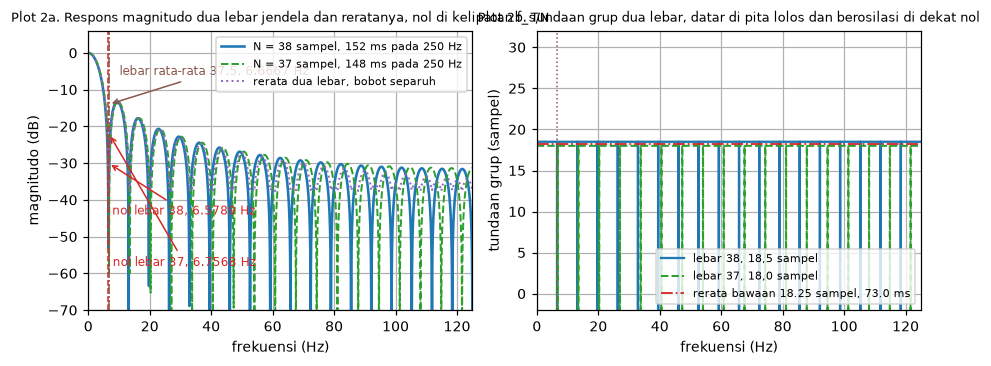

Plot 2 dicetak. Nol pertama 6.756757 Hz pada lebar 37 dan 6.578947 Hz pada lebar 38, angka perencanaan pada
lebar rata-rata 37,5 sampel 6.666667 Hz. Tundaan grup terukur bawaan 18.252283 sampel yaitu 73.009131 ms.


In [5]:
# Tujuan: memplot respons magnitudo kedua lebar jendela beserta respons reratanya, dan tundaan grupnya.
# Cell ini menampilkan Plot 2 dengan dua panel dan mencetak nol pertama per lebar, nol pertama pada lebar
# rata-rata, tundaan grup tiap lebar, dan jarak grid keluaran.

fig2, axs2 = plt.subplots(1, 2, figsize=(8.4, 3.4))
f_plot = np.linspace(0.0, FS_BOARD / 2.0, 4001)
w_plot = 2.0 * np.pi * f_plot / FS_BOARD
with np.errstate(divide="ignore", invalid="ignore"):
    mag_37 = np.abs(np.sin(N_ALT_A * w_plot / 2.0) / (N_ALT_A * np.sin(w_plot / 2.0)))
    mag_38 = np.abs(np.sin(N_ALT_B * w_plot / 2.0) / (N_ALT_B * np.sin(w_plot / 2.0)))
mag_37[0] = 1.0
mag_38[0] = 1.0
axs2[0].plot(f_plot, 20.0 * np.log10(mag_38), "C0-", lw=1.7, label="N = 38 sampel, 152 ms pada 250 Hz")
axs2[0].plot(f_plot, 20.0 * np.log10(mag_37), "C2--", lw=1.3, label="N = 37 sampel, 148 ms pada 250 Hz")
axs2[0].plot(f_plot, 20.0 * np.log10(0.5 * (mag_37 + mag_38)), "C4:", lw=1.3,
             label="rerata dua lebar, bobot separuh")
axs2[0].axvline(nol_38, color="C3", ls="--", lw=1.0)
axs2[0].axvline(nol_37, color="C3", ls=":", lw=1.0)
axs2[0].axvline(nol_bawaan, color="C5", ls="-.", lw=1.0)
axs2[0].annotate("nol lebar 38, %.4f Hz" % nol_38, xy=(nol_38, -30.0), xytext=(nol_38 + 1.2, -44.0),
                 color="C3", fontsize=8, arrowprops=dict(arrowstyle="->", color="C3"))
axs2[0].annotate("nol lebar 37, %.4f Hz" % nol_37, xy=(nol_37, -22.0), xytext=(nol_37 + 1.2, -58.0),
                 color="C3", fontsize=8, arrowprops=dict(arrowstyle="->", color="C3"))
axs2[0].annotate("lebar rata-rata 37,5, %.4f Hz" % nol_bawaan, xy=(nol_bawaan, -14.0),
                 xytext=(nol_bawaan + 3.5, -6.0), color="C5", fontsize=8,
                 arrowprops=dict(arrowstyle="->", color="C5"))
axs2[0].set_title("Plot 2a. Respons magnitudo dua lebar jendela dan reratanya, nol di kelipatan f_s/N",
                  fontsize=8.5)
axs2[0].set_xlabel("frekuensi (Hz)")
axs2[0].set_ylabel("magnitudo (dB)")
axs2[0].set_xlim(0.0, FS_BOARD / 2.0)
axs2[0].set_ylim(-70.0, 6.0)
axs2[0].legend(loc="upper right", fontsize=7.5)

w_fasa = np.linspace(1e-6, np.pi, 8000, endpoint=False)
tunda_plot_37 = -np.gradient(np.unwrap(np.angle(sg.freqz(h_37, [1.0], worN=w_fasa)[1])), w_fasa)
tunda_plot_38 = -np.gradient(np.unwrap(np.angle(sg.freqz(h_38, [1.0], worN=w_fasa)[1])), w_fasa)
axs2[1].plot(w_fasa * FS_BOARD / (2.0 * np.pi), tunda_plot_38, "C0-", lw=1.5, label="lebar 38, 18,5 sampel")
axs2[1].plot(w_fasa * FS_BOARD / (2.0 * np.pi), tunda_plot_37, "C2--", lw=1.3, label="lebar 37, 18,0 sampel")
axs2[1].axhline(tunda_bawaan, color="C3", ls="-.", lw=1.2,
                label="rerata bawaan %.2f sampel, %.1f ms" % (tunda_bawaan, tunda_bawaan * 1000.0 / FS_BOARD))
axs2[1].axvline(nol_bawaan, color="C5", ls=":", lw=1.0)
axs2[1].set_title("Plot 2b. Tundaan grup dua lebar, datar di pita lolos dan berosilasi di dekat nol",
                  fontsize=8.5)
axs2[1].set_xlabel("frekuensi (Hz)")
axs2[1].set_ylabel("tundaan grup (sampel)")
axs2[1].set_xlim(0.0, FS_BOARD / 2.0)
axs2[1].set_ylim(-2.0, 32.0)
axs2[1].legend(loc="lower right", fontsize=7.5)
fig2.tight_layout()
plt.show()
print("Plot 2 dicetak. Nol pertama %.6f Hz pada lebar 37 dan %.6f Hz pada lebar 38, angka perencanaan pada"
      % (nol_37, nol_38))
print("lebar rata-rata 37,5 sampel %.6f Hz. Tundaan grup terukur bawaan %.6f sampel yaitu %.6f ms."
      % (nol_bawaan, tunda_ukur_bawaan, tunda_ukur_bawaan * 1000.0 / FS_BOARD))


## 5. Lebar jendela pada beberapa laju sampel

Makalah menetapkan 150 ms dan 30 sampel pada 200 Hz, dengan aturan bahwa lebar jendela kira-kira sama
dengan QRS terlebar yang mungkin, dan bahwa lebar itu ditentukan secara empiris. Kalau tetapan
waktunya yang dipertahankan, lebar dalam sampel harus diskalakan dengan laju sampel:

$$ N = 0{,}150 \ f_s $$

Pada laju terkunci tim 250 Hz hasilnya 37,5 sampel. Angka pecahan itu harus diselesaikan dengan cara
yang dapat dibangun di perangkat keras, dan konvensi terkunci memilih dua jendela bergantian 37 sampel
dan 38 sampel, sehingga panjang rata-ratanya tepat 150 ms:

$$ \frac{37 + 38}{2} = 37{,}5 \ \text{sampel} = 150 \ \text{ms} $$

Jendela tetap 37 sampel memberi 148,0 ms, dan jendela tetap 38 sampel memberi 152,0 ms, jadi keduanya
menyimpang 2 ms dari 150 ms. Jendela bergantian tidak menyimpang pada panjang rata-ratanya, dan itulah
alasan bentuk itu dikunci sebagai bawaan.

Tabel lebar jendela pada beberapa laju sampel ada di sel berikut, bersama pembagian 150 ms pada 250 Hz
menjadi pasangan 37 dan 38. Sel sesudahnya menjawab pertanyaan yang paling sering muncul untuk tahap
ini: mengapa 32 sampel, yang pangkat dua dan enak dibagi dengan geser, tidak dipakai. Jawabannya
angka: 32 sampel pada 250 Hz hanya 128,0 ms, yaitu 22 milidetik lebih pendek dari 150 ms. Pembandingan
lengkap ketiga pilihan lebar bulat beserta pilihan 32 sampel ada pada satu sel ringkas di akhir
bagian 7.


In [6]:
# Tujuan: menghitung lebar jendela 150 ms pada beberapa laju sampel dan membagi 150 ms pada 250 Hz menjadi
# pasangan lebar 37 dan 38 sampel.
# Cell ini mencetak tabel lebar jendela per laju sampel dalam sampel dan milidetik, lebar tepat pada 250 Hz,
# penyimpangan lebar tetap 37 dan tetap 38, dan panjang rata-rata pasangan bergantian.

laju_uji = np.array([100.0, 125.0, 200.0, 250.0, 360.0, 500.0])
lebar_tepat = 0.150 * laju_uji
lebar_bulat = np.round(lebar_tepat).astype(int)
df_lebar = pd.DataFrame({
    "laju sampel (Hz)": laju_uji.astype(int),
    "lebar 150 ms (sampel)": lebar_tepat,
    "dibulatkan (sampel)": lebar_bulat,
    "panjang dibulatkan (ms)": lebar_bulat / laju_uji * 1000.0,
    "galat terhadap 150 ms (ms)": lebar_bulat / laju_uji * 1000.0 - 150.0,
})
print("tabel lebar jendela 150 ms pada beberapa laju sampel:")
print(df_lebar.to_string(index=False))
print()

ms_37 = N_ALT_A / FS_BOARD * 1000.0
ms_38 = N_ALT_B / FS_BOARD * 1000.0
ms_bawaan = N_ALT_MEAN / FS_BOARD * 1000.0
print("pada laju terkunci %.1f Hz, 150 ms menjadi %.6f sampel, jadi tidak bulat:" % (FS_BOARD, 0.150 * FS_BOARD))
print("  lebar tetap 37 sampel          : %.4f ms, penyimpangan %+.4f ms" % (ms_37, ms_37 - 150.0))
print("  lebar tetap 38 sampel          : %.4f ms, penyimpangan %+.4f ms" % (ms_38, ms_38 - 150.0))
print("  pasangan bergantian 37 dan 38  : %.4f ms pada rata-rata %.1f sampel, penyimpangan %+.4f ms"
      % (ms_bawaan, N_ALT_MEAN, ms_bawaan - 150.0))
print("  jadi pasangan bergantian itulah yang dipakai sebagai bawaan, dengan lebar terbesar %d sampel"
      % N_SIZING)
print("  catatan: penyimpangan nol itu sifat rata-rata, bukan sifat tiap sampel, karena lebar jendelanya"
      " masih berganti setiap sampel")

assert int(lebar_bulat[np.argmin(np.abs(laju_uji - 200.0))]) == N_PAPER, "30 sampel di 200 Hz"
assert abs(ms_bawaan - 150.0) < 1e-9, "panjang rata-rata pasangan harus 150 ms"
assert abs(ms_37 - 148.0) < 1e-9 and abs(ms_38 - 152.0) < 1e-9, "lebar tetap harus menyimpang 2 ms"
HASIL["lebar jendela pada 200 Hz (sampel)"] = N_PAPER
HASIL["lebar jendela pada 250 Hz (sampel)"] = 0.150 * FS_BOARD
HASIL["lebar rata-rata skema bergantian (ms)"] = ms_bawaan
HASIL["galat tetap 37 terhadap 150 ms (ms)"] = ms_37 - 150.0
HASIL["galat tetap 38 terhadap 150 ms (ms)"] = ms_38 - 150.0
print("lolos: 30 sampel pada 200 Hz, 37,5 sampel pada 250 Hz, dan pasangan bergantian panjangnya %.4f ms"
      % ms_bawaan)


tabel lebar jendela 150 ms pada beberapa laju sampel:
 laju sampel (Hz)  lebar 150 ms (sampel)  dibulatkan (sampel)  panjang dibulatkan (ms)  galat terhadap 150 ms (ms)
              100                  15.00                   15                    150.0                         0.0
              125                  18.75                   19                    152.0                         2.0
              200                  30.00                   30                    150.0                         0.0
              250                  37.50                   38                    152.0                         2.0
              360                  54.00                   54                    150.0                         0.0
              500                  75.00                   75                    150.0                         0.0

pada laju terkunci 250.0 Hz, 150 ms menjadi 37.500000 sampel, jadi tidak bulat:
  lebar tetap 37 sampel          : 148.0000 ms, penyimpangan

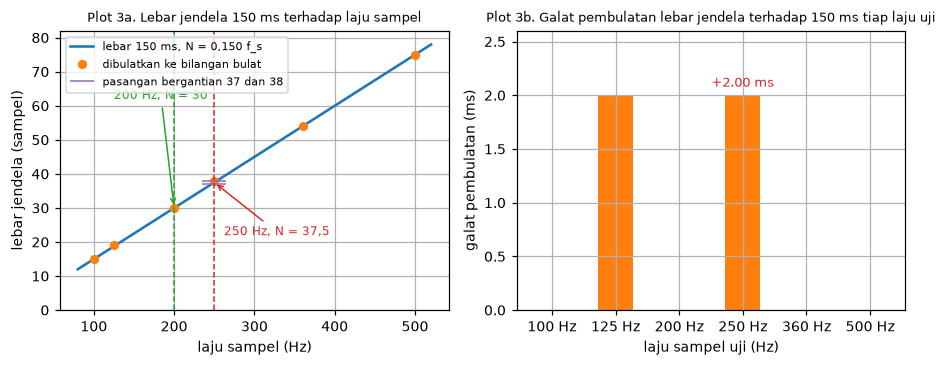

Plot 3 dicetak. Galat pembulatan terbesar 2.0000 ms muncul pada 125 Hz, 250 Hz.
Pada laju terkunci 250 Hz, lebar bulat tunggal terdekat 38 sampel memberi 152.0000 ms, jadi bergeser 2.0000 ms.
bagian pecahan lebar tepat tiap laju: 100 Hz 0.0000, 125 Hz 0.7500, 200 Hz 0.0000, 250 Hz 0.5000, 360 Hz 0.0000, 500 Hz 0.0000
pembacaan bagian pecahan itu:
  laju dengan pecahan 0,00 memberi lebar bulat tunggal yang eksak 150,0 ms: 100 Hz, 200 Hz, 360 Hz, 500 Hz
  laju dengan pecahan 0,50 memberi 150,0 ms hanya lewat pasangan dua lebar berurutan: 250 Hz
  laju dengan pecahan lain, yaitu 125 Hz, tidak bisa mencapai 150,0 ms baik dengan satu lebar maupun pasangan
  sebabnya, pada 125 Hz lebar tepatnya 18,75 sampel, sehingga pasangan 18 dan 19 hanya memberi 148.0 ms
  jadi pada laju terkunci 250 Hz, yang pecahannya 0,50, pasangan bergantian 37 dan 38 itulah pilihan yang
  memberi panjang rata-rata tepat 150,0 ms, sedangkan satu lebar tunggal tidak bisa.


In [7]:
# Tujuan: memplot lebar jendela 150 ms terhadap laju sampel dan galat pembulatan lebar pada tiap laju uji.
# Cell ini menampilkan Plot 3 dengan dua panel dan mencetak laju sampel yang galat pembulatannya terbesar.

fig3, axs3 = plt.subplots(1, 2, figsize=(8.4, 3.4))
laju_halus = np.linspace(80.0, 520.0, 601)
axs3[0].plot(laju_halus, 0.150 * laju_halus, "C0-", lw=1.7, label="lebar 150 ms, N = 0,150 f_s")
axs3[0].plot(laju_uji, lebar_bulat, "C1o", ms=5, label="dibulatkan ke bilangan bulat")
axs3[0].plot([FS_BOARD, FS_BOARD], [N_ALT_A, N_ALT_B], "C4_", ms=16, lw=2.0,
             label="pasangan bergantian 37 dan 38")
axs3[0].axvline(FS_PAPER, color="C2", ls="--", lw=1.0)
axs3[0].axvline(FS_BOARD, color="C3", ls="--", lw=1.0)
axs3[0].annotate("200 Hz, N = 30", xy=(FS_PAPER, 30.0), xytext=(FS_PAPER - 75.0, 62.0),
                 color="C2", fontsize=8, arrowprops=dict(arrowstyle="->", color="C2"))
axs3[0].annotate("250 Hz, N = 37,5", xy=(FS_BOARD, 37.5), xytext=(FS_BOARD + 12.0, 22.0),
                 color="C3", fontsize=8, arrowprops=dict(arrowstyle="->", color="C3"))
axs3[0].set_title("Plot 3a. Lebar jendela 150 ms terhadap laju sampel", fontsize=8.5)
axs3[0].set_xlabel("laju sampel (Hz)")
axs3[0].set_ylabel("lebar jendela (sampel)")
axs3[0].set_ylim(0.0, 82.0)
axs3[0].legend(loc="upper left", fontsize=7.5)

galat_bulat = np.abs(df_lebar["galat terhadap 150 ms (ms)"].to_numpy())
axs3[1].bar(["%d Hz" % s for s in laju_uji.astype(int)], galat_bulat, color=["C1"] * laju_uji.size, width=0.55)
axs3[1].annotate("%+.2f ms" % df_lebar["galat terhadap 150 ms (ms)"][np.argmin(np.abs(laju_uji - 250.0))],
                 xy=(np.argmin(np.abs(laju_uji - 250.0)), galat_bulat[np.argmin(np.abs(laju_uji - 250.0))] + 0.08),
                 ha="center", color="C3", fontsize=8.5)
axs3[1].set_title("Plot 3b. Galat pembulatan lebar jendela terhadap 150 ms tiap laju uji", fontsize=8.5)
axs3[1].set_xlabel("laju sampel uji (Hz)")
axs3[1].set_ylabel("galat pembulatan (ms)")
axs3[1].set_ylim(0.0, 2.6)
fig3.tight_layout()
plt.show()
pecahan_lebar = lebar_tepat - np.floor(lebar_tepat)
laju_galat_besar = laju_uji[galat_bulat >= float(galat_bulat.max()) - 1e-12].astype(int)
print("Plot 3 dicetak. Galat pembulatan terbesar %.4f ms muncul pada %s."
      % (float(galat_bulat.max()), ", ".join("%d Hz" % s for s in laju_galat_besar)))
print("Pada laju terkunci %d Hz, lebar bulat tunggal terdekat %d sampel memberi %.4f ms, jadi bergeser %.4f ms."
      % (int(FS_BOARD), N_ALT_B, float(ms_38), float(ms_38 - 150.0)))
print("bagian pecahan lebar tepat tiap laju: %s"
      % ", ".join("%d Hz %.4f" % (laju_uji[i], pecahan_lebar[i]) for i in range(laju_uji.size)))
laju_eksak = laju_uji[pecahan_lebar == 0.0].astype(int)
laju_pasangan = laju_uji[pecahan_lebar == 0.5].astype(int)
print("pembacaan bagian pecahan itu:")
print("  laju dengan pecahan 0,00 memberi lebar bulat tunggal yang eksak 150,0 ms: %s"
      % ", ".join("%d Hz" % s for s in laju_eksak))
print("  laju dengan pecahan 0,50 memberi 150,0 ms hanya lewat pasangan dua lebar berurutan: %s"
      % ", ".join("%d Hz" % s for s in laju_pasangan))
print("  laju dengan pecahan lain, yaitu %s, tidak bisa mencapai 150,0 ms baik dengan satu lebar maupun pasangan"
      % ", ".join("%d Hz" % s for s in laju_uji[pecahan_lebar > 0.5].astype(int)))
print("  sebabnya, pada 125 Hz lebar tepatnya 18,75 sampel, sehingga pasangan 18 dan 19 hanya memberi %.1f ms"
      % ((18 + 19) / 2.0 / 125.0 * 1000.0))
print("  jadi pada laju terkunci %d Hz, yang pecahannya 0,50, pasangan bergantian %d dan %d itulah pilihan yang"
      % (int(FS_BOARD), N_ALT_A, N_ALT_B))
print("  memberi panjang rata-rata tepat 150,0 ms, sedangkan satu lebar tunggal tidak bisa."
      )
assert abs(float(pecahan_lebar[np.argmin(np.abs(laju_uji - FS_BOARD))]) - 0.5) < 1e-12, "250 Hz harus berpecahan 0,5"


In [8]:
# Tujuan: menjelaskan dengan angka mengapa pilihan 32 sampel tidak dipakai.
# Cell ini mencetak panjang 32 sampel pada 250 Hz dan penyimpangannya terhadap 150 ms, nol pertama dan tundaan
# grupnya, respons dua lebar pada 10 Hz dan 20 Hz, serta biaya penjumlahan bentuk langsungnya.

ms_32 = N32 / FS_BOARD * 1000.0
penyimpangan_32 = ms_32 - 150.0
tunda_32 = (N32 - 1) / 2.0
tunda_bawaan_ms = 0.5 * ((N_ALT_A - 1) / 2.0 + (N_ALT_B - 1) / 2.0)


def respons_jendela(N, f):
    """magnitudo respons jendela rata-rata panjang N pada frekuensi f"""
    w = 2.0 * np.pi * f / FS_BOARD
    with np.errstate(divide="ignore", invalid="ignore"):
        return float(abs(np.sin(N * w / 2.0) / (N * np.sin(w / 2.0))))


print("mengapa 32 sampel tidak dipakai, padahal 32 pangkat dua dan pembagiannya bisa digeser:")
print("  32 sampel pada %.1f Hz     : %.4f ms, penyimpangan %+.4f ms yaitu %+.4f persen terhadap 150 ms"
      % (FS_BOARD, ms_32, penyimpangan_32, 100.0 * penyimpangan_32 / 150.0))
print("  37 sampel pada %.1f Hz     : %.4f ms, penyimpangan %+.4f ms" % (FS_BOARD, ms_37, ms_37 - 150.0))
print("  38 sampel pada %.1f Hz     : %.4f ms, penyimpangan %+.4f ms" % (FS_BOARD, ms_38, ms_38 - 150.0))
print("  bergantian 37 dan 38       : %.4f ms, penyimpangan %+.4f ms"
      % (ms_bawaan, ms_bawaan - 150.0))
print()
print("akibatnya pada tapis, dibandingkan lebar bawaan:")
print("  nol pertama 32 sampel      : %.6f Hz, sedangkan lebar rata-rata bawaan %.6f Hz, selisih %.6f Hz"
      % (FS_BOARD / N32, nol_bawaan, FS_BOARD / N32 - nol_bawaan))
print("  tundaan grup 32 sampel     : %.4f sampel = %.4f ms, sedangkan bawaan %.4f sampel = %.4f ms"
      % (tunda_32, tunda_32 * 1000.0 / FS_BOARD, tunda_bawaan_ms, tunda_bawaan_ms * 1000.0 / FS_BOARD))
print("    jadi tundaan 32 sampel %.4f ms lebih pendek" % (tunda_bawaan_ms * 1000.0 / FS_BOARD - tunda_32 * 1000.0 / FS_BOARD))
print("  respons pada 10 Hz         : 32 sampel %.6f (%+.4f dB), 37 sampel %.6f (%+.4f dB), 38 sampel %.6f (%+.4f dB)"
      % (respons_jendela(N32, 10.0), 20.0 * np.log10(respons_jendela(N32, 10.0)),
         respons_jendela(N_ALT_A, 10.0), 20.0 * np.log10(respons_jendela(N_ALT_A, 10.0)),
         respons_jendela(N_ALT_B, 10.0), 20.0 * np.log10(respons_jendela(N_ALT_B, 10.0))))
print("  respons pada 20 Hz         : 32 sampel %.6f (%+.4f dB), 37 sampel %.6f (%+.4f dB), 38 sampel %.6f (%+.4f dB)"
      % (respons_jendela(N32, 20.0), 20.0 * np.log10(respons_jendela(N32, 20.0)),
         respons_jendela(N_ALT_A, 20.0), 20.0 * np.log10(respons_jendela(N_ALT_A, 20.0)),
         respons_jendela(N_ALT_B, 20.0), 20.0 * np.log10(respons_jendela(N_ALT_B, 20.0))))
print("  jadi 32 sampel melewatkan pita 20 Hz sekitar %.4f dB lebih kuat dari lebar bawaan, dan pita itulah"
      % (20.0 * np.log10(respons_jendela(N_ALT_B, 20.0)) - 20.0 * np.log10(respons_jendela(N32, 20.0))))
print("  tempat gelombang T dan sisa derau otot berada")
print()
print("biaya bentuk langsung: 32 suku butuh 32 penjumlahan per sampel, 37 suku butuh 37 penjumlahan per sampel")
print("  penampan melingkar bawaan tetap 1 tambah dan 1 kurang per sampel, tidak bergantung lebar, dan")
print("  pembagian 38 tidak dikerjakan karena ambangnya yang dikalikan 38, jadi keunggulan pangkat dua")
print("  pada pembagian hilang sepenuhnya.")

assert abs(penyimpangan_32 + 22.0) < 1e-9, "32 sampel harus menyimpang 22 ms"
assert respons_jendela(N32, 20.0) > 5.0 * respons_jendela(N_ALT_B, 20.0), "32 sampel harus melewatkan 20 Hz lebih kuat"
HASIL["lebar 32 sampel (ms)"] = ms_32
HASIL["penyimpangan lebar 32 sampel (ms)"] = penyimpangan_32
HASIL["respons 32 sampel pada 20 Hz (dB)"] = 20.0 * np.log10(respons_jendela(N32, 20.0))
HASIL["respons 38 sampel pada 20 Hz (dB)"] = 20.0 * np.log10(respons_jendela(N_ALT_B, 20.0))
print("lolos: 32 sampel menyimpang %.4f ms dari 150 ms, dan pita 20 Hz dilewatkan %.4f dB lebih kuat"
      % (penyimpangan_32, 20.0 * np.log10(respons_jendela(N_ALT_B, 20.0)) - 20.0 * np.log10(respons_jendela(N32, 20.0))))


mengapa 32 sampel tidak dipakai, padahal 32 pangkat dua dan pembagiannya bisa digeser:
  32 sampel pada 250.0 Hz     : 128.0000 ms, penyimpangan -22.0000 ms yaitu -14.6667 persen terhadap 150 ms
  37 sampel pada 250.0 Hz     : 148.0000 ms, penyimpangan -2.0000 ms
  38 sampel pada 250.0 Hz     : 152.0000 ms, penyimpangan +2.0000 ms
  bergantian 37 dan 38       : 150.0000 ms, penyimpangan +0.0000 ms

akibatnya pada tapis, dibandingkan lebar bawaan:
  nol pertama 32 sampel      : 7.812500 Hz, sedangkan lebar rata-rata bawaan 6.666667 Hz, selisih 1.145833 Hz
  tundaan grup 32 sampel     : 15.5000 sampel = 62.0000 ms, sedangkan bawaan 18.2500 sampel = 73.0000 ms
    jadi tundaan 32 sampel 11.0000 ms lebih pendek
  respons pada 10 Hz         : 32 sampel 0.192116 (-14.3287 dB), 37 sampel 0.215216 (-13.3425 dB), 38 sampel 0.209552 (-13.5742 dB)
  respons pada 20 Hz         : 32 sampel 0.123433 (-18.1714 dB), 37 sampel 0.013621 (-37.3159 dB), 38 sampel 0.013262 (-37.5475 dB)
  jadi 32 sampel me

## 6. Hitungan tangan rata-rata bergerak

Dua bentuk persamaan (11) harus dibedakan dengan jelas, karena keduanya dipakai di perangkat keras
dan keduanya memberi angka yang sama:

1. Bentuk langsung, yaitu jumlah seluruh sampel di dalam jendela lalu dibagi $N$, seperti tertulis di
   makalah.
2. Bentuk rekursif, yaitu satu penjumlahan dan satu pengurangan per sampel, dengan normalisasi
   dikerjakan di luar:

$$ S[n] = S[n-1] + x[n] - x[n-N] $$

Bentuk rekursif ini yang dipakai di RTL, karena biayanya tetap dua operasi per sampel, tidak
bergantung pada $N$. Pada $N = 38$ bentuk langsung butuh 38 penjumlahan per sampel, sedangkan bentuk
rekursif butuh dua. Keduanya diuji sama eksak pada larik bilangan bulat, jadi klaim kesamaannya tidak
memerlukan toleransi.

Struktur jendela yang dipakai adalah penampan melingkar: penampan 38 kata dengan penunjuk tulis yang
berputar modulo 38. Akumulatornya memegang jumlah 38 sampel terakhir, sehingga biayanya tetap satu
tambah dan satu kurang per sampel, tidak bergantung pada lebar jendela. Keluaran lebar 37 dibentuk satu
kurang tambahan di jalur keluaran, dipilih bit paritas, jadi keadaan akumulatornya tidak berubah.
Karena pembagian 38 tidak dilakukan, tidak ada pembagi di jalur ini: jumlahnya dibandingkan dengan
ambang yang sudah dikalikan 38.

Satu catatan terukur yang perlu ditegaskan, karena mudah salah: bentuk rekursif dengan tap yang
berganti, yaitu $S[n] = S[n-1] + x[n] - x[n - w_n]$, tidak sama dengan jumlah jendela bergantian,
karena tepi bawah jendela tidak maju satu sampel setiap langkah. Sel berikut mencetak galatnya. Yang
eksak adalah penampan melingkar: akumulator lebar 38 dengan satu tambah dan satu kurang per sampel,
ditambah satu kurang di jalur keluaran pada paritas lebar sempit.

Tiga sel berikut meniru perhitungan tangan: satu tabel dengan $N = 5$ supaya seluruh suku muat di
layar, satu sel rekursif dengan $N = 38$ pada larik bilangan bulat yang juga memuat galat rekursi
bergantian, dan satu sel penampan melingkar yang mencetak jejak penunjuk tulisnya beserta biaya
penyimpanannya dalam flip-flop.


In [9]:
# Tujuan: menghitung rata-rata bergerak langsung dengan N = 5 sebagai contoh soal agar seluruh suku muat di tabel.
# Cell ini mencetak tabel n = 0 sampai 14 dengan satu kolom per suku jendela, pembacaan satu baris, dan hasil
# pemeriksaannya terhadap jumlah langsung.

N_CONTOH = 5
x_tangan = np.array([3, 1, 4, 1, 5, 9, 2, 6, 5, 3, 5, 8, 9, 7, 9], dtype=np.int64)


def tabel_jendela(x_in, n_jendela):
    """tabel contoh soal, satu kolom per suku jendela, jumlahnya, dan keluaran sesudah dibagi n_jendela"""
    def xv(i):
        return 0 if i < 0 or i >= x_in.size else int(x_in[i])
    baris = []
    for n in range(x_in.size):
        suku = [xv(n - k) for k in range(n_jendela)]
        jumlah = int(np.sum(suku))
        baris.append({"n": n, "x[n]": suku[0], "x[n-1]": suku[1], "x[n-2]": suku[2], "x[n-3]": suku[3],
                      "x[n-4]": suku[4], "S[n]": jumlah,
                      "y[n] = S[n]/%d" % n_jendela: jumlah / float(n_jendela)})
    return pd.DataFrame(baris)


df_contoh = tabel_jendela(x_tangan, N_CONTOH)
print("contoh soal, rata-rata bergerak N = %d, masukan bilangan bulat:" % N_CONTOH)
print(df_contoh.to_string(index=False))
print()

n_contoh = 12
indeks_contoh = [n_contoh - k for k in range(N_CONTOH)]
nilai_contoh = [int(x_tangan[i]) for i in indeks_contoh]
print("baris n = %d dibaca begini: suku %s jumlahnya %d dan dibagi %d menjadi %.1f"
      % (n_contoh, " ".join("x[%d] = %d" % (i, v) for i, v in zip(indeks_contoh, nilai_contoh)),
         int(np.sum(nilai_contoh)), N_CONTOH, np.sum(nilai_contoh) / float(N_CONTOH)))
jumlah_langsung = np.array([np.sum([int(x_tangan[i]) for i in range(n - N_CONTOH + 1, n + 1)
                                    if 0 <= i < x_tangan.size]) for n in range(x_tangan.size)], dtype=np.int64)
sama_contoh = bool(np.array_equal(jumlah_langsung, df_contoh["S[n]"].to_numpy(dtype=np.int64)))
print("jumlah %d suku pada baris n = %d sama dengan x[%d] sampai x[%d] : %s"
      % (N_CONTOH, n_contoh, n_contoh - N_CONTOH + 1, n_contoh, sama_contoh))

assert sama_contoh, "kolom jumlah tabel harus sama dengan jumlah langsung lima sampel"
assert int(df_contoh["S[n]"][n_contoh]) == int(np.sum(nilai_contoh)), "baris contoh harus cocok"
HASIL["contoh soal N"] = N_CONTOH
print("lolos: contoh soal N = %d konsisten antara jumlah lima suku dan bentuk tabel" % N_CONTOH)


contoh soal, rata-rata bergerak N = 5, masukan bilangan bulat:
 n  x[n]  x[n-1]  x[n-2]  x[n-3]  x[n-4]  S[n]  y[n] = S[n]/5
 0     3       0       0       0       0     3            0.6
 1     1       3       0       0       0     4            0.8
 2     4       1       3       0       0     8            1.6
 3     1       4       1       3       0     9            1.8
 4     5       1       4       1       3    14            2.8
 5     9       5       1       4       1    20            4.0
 6     2       9       5       1       4    21            4.2
 7     6       2       9       5       1    23            4.6
 8     5       6       2       9       5    27            5.4
 9     3       5       6       2       9    25            5.0
10     5       3       5       6       2    21            4.2
11     8       5       3       5       6    27            5.4
12     9       8       5       3       5    30            6.0
13     7       9       8       5       3    32            6.4
14     

In [10]:
# Tujuan: membuktikan bentuk rekursif sama eksak dengan bentuk langsung, membandingkan dengan rekursi tap
# bergantian yang tidak eksak, dan memverifikasi penampan melingkar bawaan.
# Cell ini mencetak galat maksimum bentuk rekursif tetap 38, galat rekursi bergantian, galat penampan
# melingkar lawan jendela bergantian, rincian suku jendela terlebar pada satu sampel, dan bentuk kausal lawan
# bentuk terpusat.

rng_tangan = np.random.default_rng(29)
x_tangan = rng_tangan.integers(-500, 501, 4000).astype(np.int64)
S_langsung = jendela_jumlah(x_tangan, N_ALT_B)
S_rekursif = np.concatenate([[0], S_langsung[:-1]]) + x_tangan - geser_kiri(x_tangan, N_ALT_B)
galat_rekursif = int(np.max(np.abs(S_langsung - S_rekursif)))
print("bentuk langsung lawan bentuk rekursif, lebar tetap 38, masukan bilangan bulat")
print("  panjang larik uji            :", x_tangan.size)
print("  rentang nilai masukan        :", int(x_tangan.min()), "sampai", int(x_tangan.max()))
print("  galat maksimum               :", galat_rekursif)

# rekursi dengan tap yang berganti, untuk menunjukkan bahwa bentuk itu tidak sama dengan jendela bergantian
lebar_berganti = np.where(np.arange(x_tangan.size) % 2 == 0, N_ALT_A, N_ALT_B)
S_naif = np.zeros(x_tangan.size, dtype=np.int64)
for n in range(x_tangan.size):
    keluar_naif = int(x_tangan[n - int(lebar_berganti[n])]) if n - int(lebar_berganti[n]) >= 0 else 0
    S_naif[n] = S_naif[n - 1] + int(x_tangan[n]) - keluar_naif
S_alt_tangan = jendela_bergantian(x_tangan)
galat_naif = int(np.max(np.abs(S_alt_tangan - S_naif)))
print("  galat rekursi tap bergantian : %d, yaitu %.4f persen puncak jumlah"
      % (galat_naif, 100.0 * galat_naif / float(np.abs(S_alt_tangan).max())))

S_cincin, tambah_cincin, kurang_cincin, kurang_keluaran = selubung_bawaan(x_tangan)
galat_cincin = int(np.max(np.abs(S_alt_tangan - S_cincin)))
print("penampan melingkar bawaan, lebar akumulator %d dan keluaran bergantian:" % N_SIZING)
print("  panjang larik uji            :", x_tangan.size)
print("  galat lawan jendela bergantian langsung :", galat_cincin)
print("  operasi tambah per sampel    : %.2f" % (tambah_cincin / x_tangan.size))
print("  operasi kurang per sampel    : %.2f, yaitu %.2f kurang tambahan di jalur keluaran per dua sampel"
      % (kurang_cincin / x_tangan.size, kurang_keluaran / x_tangan.size * 2.0))

n_rinci = 1234
suku_rinci = x_tangan[n_rinci - N_ALT_B + 1: n_rinci + 1]
jumlah_rinci = int(suku_rinci.sum())
print()
print("rincian seluruh", N_ALT_B, "suku jendela terlebar pada sampel n =", n_rinci)
print("  sampel pertama jendela n =", n_rinci - N_ALT_B + 1, "bernilai", int(suku_rinci[0]))
print("  sampel terakhir jendela n =", n_rinci, "bernilai", int(suku_rinci[-1]))
print("  seluruh suku                 :", suku_rinci)
print("  jumlah 38 suku              :", jumlah_rinci)
print("  dibagi 38                    :", jumlah_rinci / N_ALT_B, "dihitung di sini hanya sebagai ilustrasi,"
      " pembagiannya tidak dikerjakan di RTL")
print("  sisa pembagian               :", jumlah_rinci % N_ALT_B)
print("  S[n] dari bentuk langsung    :", int(S_langsung[n_rinci]))
print("  jumlah suku sama dengan bentuk langsung :", bool(jumlah_rinci == int(S_langsung[n_rinci])))

impuls_uji = np.zeros(200, dtype=np.int64)
impuls_uji[100] = 1000
S_kausal_uji = selubung_bawaan(impuls_uji)[0]
S_terpusat_uji = np.convolve(impuls_uji, np.ones(N_ALT_B, dtype=np.int64), mode="same")
puncak_kausal = int(np.argmax(S_kausal_uji))
puncak_terpusat = int(np.argmax(S_terpusat_uji))
print()
print("bentuk kausal persamaan (11) lawan bentuk terpusat, masukan impuls di indeks 100")
print("  puncak bentuk kausal bawaan         : indeks %d, nilai %d" % (puncak_kausal, int(S_kausal_uji[puncak_kausal])))
print("  puncak bentuk terpusat, mode same   : indeks %d, nilai %d" % (puncak_terpusat, int(S_terpusat_uji[puncak_terpusat])))
print("  selisih posisi puncak               : %d sampel, yaitu %.1f ms"
      % (puncak_kausal - puncak_terpusat, (puncak_kausal - puncak_terpusat) * 1000.0 / FS_BOARD))
print("  jadi bentuk terpusat menggeser puncak lebih awal %.1f ms, dan bentuk kausal itulah yang dipakai"
      % ((puncak_kausal - puncak_terpusat) * 1000.0 / FS_BOARD))

assert galat_rekursif == 0, "bentuk rekursif lebar tetap harus sama eksak"
assert galat_cincin == 0, "penampan melingkar harus sama eksak dengan jendela bergantian langsung"
assert galat_naif > 0, "rekursi tap bergantian memang tidak sama dengan jendela bergantian"
assert jumlah_rinci == int(S_langsung[n_rinci]), "jumlah 38 suku harus sama dengan bentuk langsung"
assert puncak_kausal == 100, "bentuk kausal bawaan harus menaruh puncak tepat di indeks impuls"
HASIL["galat bentuk rekursif jendela"] = galat_rekursif
HASIL["galat rekursi tap bergantian"] = galat_naif
HASIL["galat penampan melingkar lawan jendela bergantian"] = galat_cincin
HASIL["lebar terbesar jendela (sampel)"] = N_SIZING
HASIL["selisih puncak kausal lawan terpusat (sampel)"] = puncak_kausal - puncak_terpusat
HASIL["puncak kausal pada indeks"] = puncak_kausal
HASIL["puncak terpusat pada indeks"] = puncak_terpusat
print("lolos: rekursif tetap 38 eksak, penampan melingkar eksak lawan jendela bergantian,")
print("dan rekursi tap bergantian memang tidak eksak dengan galat %d" % galat_naif)


bentuk langsung lawan bentuk rekursif, lebar tetap 38, masukan bilangan bulat
  panjang larik uji            : 4000
  rentang nilai masukan        : -500 sampai 500
  galat maksimum               : 0
  galat rekursi tap bergantian : 33742, yaitu 545.9871 persen puncak jumlah
penampan melingkar bawaan, lebar akumulator 38 dan keluaran bergantian:
  panjang larik uji            : 4000
  galat lawan jendela bergantian langsung : 0
  operasi tambah per sampel    : 1.00
  operasi kurang per sampel    : 1.00, yaitu 1.00 kurang tambahan di jalur keluaran per dua sampel

rincian seluruh 38 suku jendela terlebar pada sampel n = 1234
  sampel pertama jendela n = 1197 bernilai 327
  sampel terakhir jendela n = 1234 bernilai -191
  seluruh suku                 : [ 327  -43   -2  134  420 -114 -232  173  133 -154 -141 -109 -318  163
 -402   53  290  -48   83 -403 -449  427  131  -68   68  250   78   42
 -411 -230 -158 -323 -450   61   99   58  296 -191]
  jumlah 38 suku              : -960
  dibagi

In [11]:
# Tujuan: memperlihatkan struktur penampan melingkar, yaitu satu tambah dan satu kurang per sampel, dan
# mencetak biaya penyimpanannya dalam flip-flop.
# Cell ini mencetak jejak penunjuk tulis penampan, jumlah operasi tiap sampel, biaya simpan dalam flip-flop
# untuk lebar kata yang dipakai, angka demo integrator hasil sintesis sebagai pembanding, dan status
# keputusan flip-flop lawan BRAM.

x_jejak = np.arange(48, dtype=np.int64) + 1
buf_jejak = np.zeros(N_SIZING, dtype=np.int64)
head_jejak = 0
acc_jejak = 0
jendela_jejak = jendela_bergantian(x_jejak)
print("jejak penampan melingkar, kedalaman %d kata, masukan tanjakan, delapan langkah:" % N_SIZING)
for n in range(x_jejak.size):
    lebar_j = N_ALT_A if n % 2 == 0 else N_ALT_B
    keluar_j = int(buf_jejak[head_jejak])
    acc_j = acc_jejak + int(x_jejak[n]) - keluar_j
    buf_jejak[head_jejak] = x_jejak[n]
    head_jejak = (head_jejak + 1) % N_SIZING
    keluaran_j = acc_j - int(buf_jejak[head_jejak]) if lebar_j < N_SIZING else acc_j
    if 36 <= n <= 43:
        print("  n %2d, lebar %d, masuk %2d, keluar %2d, akumulator %5d, selubung %5d, jendela langsung %5d,"
              " penunjuk tulis %2d"
              % (n, lebar_j, int(x_jejak[n]), keluar_j, acc_j, keluaran_j, int(jendela_jejak[n]), head_jejak))
    acc_jejak = acc_j
print("  pada n 38 penunjuk tulis kembali ke awal penampan, dan sampel yang keluar adalah x[0]")
print("  akumulator memegang %d sampel terakhir, keluaran lebar %d memakai satu kurang tambahan" % (N_SIZING, N_ALT_A))
print()

LEBAR_KATA = 32
ff_penampan = N_SIZING * LEBAR_KATA
terapan = selubung_bawaan(np.zeros(4000, dtype=np.int64))
print("biaya operasi dan penyimpanan jendela bawaan:")
print("  kedalaman penampan          : %d kata" % N_SIZING)
print("  lebar kata selubung         : %d bit, yaitu lebar yang dikunci pada geser kanan %d bit"
      % (LEBAR_KATA, SHIFT_RIGHT))
print("  operasi akumulator          : 1 tambah dan 1 kurang per sampel, tidak bergantung lebar")
print("  operasi jalur keluaran      : 1 kurang per dua sampel, dipilih bit paritas, tanpa mengubah akumulator")
print("  biaya simpan sebagai flip-flop: %d kata kali %d bit = %d flip-flop"
      % (N_SIZING, LEBAR_KATA, ff_penampan))
print("  larik panjang nol, tambah per sampel %.2f, kurang per sampel %.2f, kurang keluaran per dua sampel %.2f"
      % (terapan[1] / 4000.0, terapan[2] / 4000.0, terapan[3] / 4000.0 * 2.0))

ff_demo = None
if JALUR_LAPORAN.exists():
    teks_laporan = JALUR_LAPORAN.read_text(errors="ignore")
    cocok = re.search(r"cells mapped\s*:\s*(\d+)\s*\(flip-flops\s+(\d+),\s*combinational\s+(\d+)\)",
                      teks_laporan)
    if cocok:
        ff_demo = int(cocok.group(2))
        print()
        print("laporan sintesis demo integrator: %s" % JALUR_LAPORAN.name)
        print("  baris terbaca               :", cocok.group(0).strip())
if ff_demo is None:
    ff_demo = 482
    print("laporan sintesis tidak terbaca, dipakai angka rujukan 482 flip-flop dari brief rtl-synthesis")
print("  demo integrator penuh, 37 tap dengan pembagian 37: %d flip-flop" % ff_demo)
print("  jadi penampan melingkar ini setara %.4f kali seluruh demo integrator, selisih %d flip-flop"
      % (ff_penampan / ff_demo, ff_penampan - ff_demo))
print()
print("status keputusan: pilihan antara menaruh jendela di flip-flop, yaitu %d flip-flop seperti hitungan di"
      % ff_penampan)
print("atas, atau di BRAM, masih menunggu keputusan tim area. Notebook ini hanya mencetak biayanya, dan tidak")
print("memutuskan. Yang pasti, penampan melingkar membuat biaya operasinya tetap dua operasi per sampel.")

assert ff_penampan == N_SIZING * LEBAR_KATA, "biaya simpan harus 38 kali 32"
assert ff_penampan > 2 * ff_demo, "penampan register harus lebih mahal dari seluruh demo integrator"
HASIL["biaya penampan melingkar sebagai flip-flop"] = ff_penampan
HASIL["flip-flop demo integrator rujukan"] = ff_demo
HASIL["rasio biaya penampan lawan demo"] = ff_penampan / ff_demo
HASIL["tambah per sampel penampan melingkar"] = 1
HASIL["kurang per sampel penampan melingkar"] = 1
HASIL["kurang tambahan di jalur keluaran per dua sampel"] = 1
print("lolos: penampan melingkar %d flip-flop, demo integrator %d flip-flop, dan keputusan flip-flop lawan BRAM"
      % (ff_penampan, ff_demo))
print("masih terbuka untuk tim area")


jejak penampan melingkar, kedalaman 38 kata, masukan tanjakan, delapan langkah:
  n 36, lebar 37, masuk 37, keluar  0, akumulator   703, selubung   703, jendela langsung   703, penunjuk tulis 37
  n 37, lebar 38, masuk 38, keluar  0, akumulator   741, selubung   741, jendela langsung   741, penunjuk tulis  0
  n 38, lebar 37, masuk 39, keluar  1, akumulator   779, selubung   777, jendela langsung   777, penunjuk tulis  1
  n 39, lebar 38, masuk 40, keluar  2, akumulator   817, selubung   817, jendela langsung   817, penunjuk tulis  2
  n 40, lebar 37, masuk 41, keluar  3, akumulator   855, selubung   851, jendela langsung   851, penunjuk tulis  3
  n 41, lebar 38, masuk 42, keluar  4, akumulator   893, selubung   893, jendela langsung   893, penunjuk tulis  4
  n 42, lebar 37, masuk 43, keluar  5, akumulator   931, selubung   925, jendela langsung   925, penunjuk tulis  5
  n 43, lebar 38, masuk 44, keluar  6, akumulator   969, selubung   969, jendela langsung   969, penunjuk tulis  6


## 7. Kasus sebelum dan sesudah pada sinyal buatan, dua tingkat

Bagian ini menampilkan inti pelajaran tahap ini dalam dua tingkat, persis seperti diminta:

1. Tingkat pertama, masukan tahap ini lalu keluarannya sesudah pengkuadratan. Yang terlihat: sinyal
   yang bolak balik tanda menjadi seluruhnya positif, dan puncak QRS menjadi jauh lebih menonjol
   daripada bagian gelombang T.
2. Tingkat kedua, keluaran sesudah pengkuadratan lalu keluaran sesudah integrasi jendela bergantian
   37 dan 38 sampel. Yang terlihat: jendela itulah yang membentuk selubung energi QRS, yaitu puncak
   yang lebar dan halus dengan tepi naik yang bisa dipakai sebagai fiducial mark, bukan deretan
   puncak tajam.

Sinyalnya dibangun pada 250 Hz, 70 denyut per menit, dengan gelombang P, Q, R, S, T berbentuk
Gaussian, lalu dirusak tiga hal yang memang relevan untuk tahap ini: baseline wander 0,3 Hz,
interferensi jala-jala 50 Hz, dan derau otot pada pita 20 sampai 100 Hz. Seluruh angka dihitung pada
rantai bilangan bulat terkunci, jadi angka yang tercetak adalah angka yang akan terukur di RTL.

Dua sel berikut menampilkan kedua tingkat itu, dan bagian ini ditutup satu sel ringkas yang
membandingkan empat pilihan lebar jendela pada sinyal yang sama: bawaan bergantian 37 dan 38, tetap 37,
tetap 38, dan tetap 32. Sel ringkas itu juga mencetak selisih puncak selubung tiap pilihan dalam
persen, dan riak periode dua yang muncul pada bentuk bergantian karena lebar jendelanya berganti
setiap sampel.


In [12]:
# Tujuan: membangun sinyal buatan 250 Hz, menjalankan rantai terkunci, lalu mengukur selubung bawaan sebelum
# dan sesudah kedua tahap.
# Cell ini mencetak amplitudo tiap komponen derau, puncak tiap tahap, tabel pengukuran tiap tingkat, kekasaran
# selubung, tingkat QRS, tunda puncak, dan riak periode dua bawaan.

dur = 20.0
t = np.arange(0.0, dur, 1.0 / FS_BOARD)
rng_ecg = np.random.default_rng(7)
denyut_per_menit = 70.0
periode_denyut = 60.0 / denyut_per_menit

sinyal_bersih = np.zeros_like(t)
for i in range(int(dur / periode_denyut)):
    pusat = i * periode_denyut
    for amp, geser_waktu, sd in ((0.12, -0.20, 0.025),) + bentuk_qrs + ((0.30, 0.28, 0.075),):
        sinyal_bersih += amp * np.exp(-0.5 * ((t - (pusat + geser_waktu)) / sd) ** 2)

amp_wander, amp_mains, amp_otot = 0.08, 0.20, 0.08
pita_otot = sg.filtfilt(*sg.butter(2, [20.0 / (FS_BOARD / 2.0), 100.0 / (FS_BOARD / 2.0)], btype="band"),
                        rng_ecg.normal(0.0, 1.0, t.size))
sinyal_kotor = (sinyal_bersih
                + amp_wander * np.sin(2.0 * np.pi * 0.3 * t)
                + amp_mains * np.sin(2.0 * np.pi * 50.0 * t)
                + pita_otot / pita_otot.std() * amp_otot)

x_kata = kuantisasi(sinyal_kotor)
y_lp, y_hp, y_der = rantai_tapis(x_kata)
sq = y_der * y_der
selubung_kata, tambah_kata, kurang_kata, kurang_keluaran_kata = selubung_bawaan(sq)
galat_cincin_kata = int(np.max(np.abs(selubung_kata - jendela_bergantian(sq))))
S_37 = jendela_jumlah(sq, N_ALT_A)
S_38 = jendela_jumlah(sq, N_ALT_B)
S_32 = jendela_jumlah(sq, N32)

idx_r = []
for i in range(1, int(dur / periode_denyut)):
    pusat = i * periode_denyut
    a1, a2 = int((pusat - 0.05) * FS_BOARD), int((pusat + 0.05) * FS_BOARD)
    idx_r.append(a1 + int(np.argmax(np.abs(y_der[a1:a2]))))
idx_r = np.array(idx_r)

mask_qrs = np.zeros(t.size, dtype=bool)
for i in idx_r:
    mask_qrs[max(0, i - 25): min(t.size, i + 25)] = True
mask_qrs[:400] = False
mask_qrs[-400:] = False
luar_qrs = ~mask_qrs


def puncak_lokal(v, i, radius=50, ambang=0.2):
    """jumlah puncak lokal di atas ambang relatif, di sekitar satu denyut"""
    s = v[max(0, i - radius): i + radius].astype(float)
    return int(np.sum((s[1:-1] >= s[:-2]) & (s[1:-1] > s[2:]) & (s[1:-1] > ambang * s.max())))


def lebar_setengah(v, i, radius=100):
    """lebar dalam milidetik pada separuh puncak, di sekitar satu denyut"""
    s = v[max(0, i - radius): i + radius].astype(float)
    j = np.flatnonzero(s > 0.5 * s.max())
    return (j[-1] - j[0] + 1) / FS_BOARD * 1000.0 if j.size else 0.0


def tepi_naik(v, i, radius=100, ambang=0.1):
    """tepi naik dari ambang sampai puncak, dalam milidetik"""
    s = v[max(0, i - radius): i + radius].astype(float)
    puncak = int(np.argmax(s))
    j = np.flatnonzero(s[: puncak + 1] > ambang * s.max())
    return (puncak - j[0] + 1) / FS_BOARD * 1000.0 if j.size else 0.0


def tunda_puncak(v, i, radius=60):
    """offset puncak terhadap indeks R, dalam sampel"""
    s = v[max(0, i - radius): i + radius].astype(float)
    return int(np.argmax(s)) - radius


print("sinyal buatan : %.1f s, %d sampel, %d denyut per menit, %d denyut"
      % (dur, t.size, int(denyut_per_menit), idx_r.size))
print("amplitudo komponen: wander %.2f pada 0,3 Hz, jala-jala %.2f pada 50 Hz, otot %.2f pada 20 sampai 100 Hz"
      % (amp_wander, amp_mains, amp_otot))
print("puncak sinyal bersih %.6g, puncak kata masukan %d"
      % (float(np.max(np.abs(sinyal_bersih))), int(np.max(np.abs(x_kata)))))
print("galat penampan melingkar lawan jendela bergantian pada sinyal buatan :", galat_cincin_kata)
print("puncak turunan %d, puncak kuadrat %d, puncak selubung bawaan %d"
      % (int(np.abs(y_der).max()), int(sq.max()), int(selubung_kata.max())))
print()
print("tabel pengukuran tiap tingkat, denyut %d sampai %d dari %d denyut"
      % (4, idx_r.size, idx_r.size))
df_tingkat = pd.DataFrame([
    {"tingkat": "1 masukan tahap, keluaran turunan",
     "puncak": float(np.abs(y_der).max()),
     "puncak lokal per denyut (median)": float(np.median([puncak_lokal(np.abs(y_der), i) for i in idx_r])),
     "lebar setengah puncak (ms)": float(np.median([lebar_setengah(np.abs(y_der), i) for i in idx_r])),
     "tepi naik (ms)": float(np.median([tepi_naik(np.abs(y_der), i) for i in idx_r])),
     "tingkat QRS dibagi luar": float(np.abs(y_der)[mask_qrs].mean() / np.abs(y_der)[luar_qrs].mean())},
    {"tingkat": "1 keluaran sesudah pengkuadratan",
     "puncak": float(sq.max()),
     "puncak lokal per denyut (median)": float(np.median([puncak_lokal(sq, i) for i in idx_r])),
     "lebar setengah puncak (ms)": float(np.median([lebar_setengah(sq, i) for i in idx_r])),
     "tepi naik (ms)": float(np.median([tepi_naik(sq, i) for i in idx_r])),
     "tingkat QRS dibagi luar": float(sq[mask_qrs].mean() / sq[luar_qrs].mean())},
    {"tingkat": "2 keluaran sesudah selubung bergantian",
     "puncak": float(selubung_kata.max()),
     "puncak lokal per denyut (median)": float(np.median([puncak_lokal(selubung_kata, i) for i in idx_r])),
     "lebar setengah puncak (ms)": float(np.median([lebar_setengah(selubung_kata, i) for i in idx_r])),
     "tepi naik (ms)": float(np.median([tepi_naik(selubung_kata, i) for i in idx_r])),
     "tingkat QRS dibagi luar": float(selubung_kata[mask_qrs].mean() / selubung_kata[luar_qrs].mean())},
])
print(df_tingkat.to_string(index=False))
print()
print("tunda puncak selubung terhadap indeks R: median %.1f sampel, yaitu %.2f ms"
      % (float(np.median([tunda_puncak(selubung_kata, i) for i in idx_r])),
         float(np.median([tunda_puncak(selubung_kata, i) for i in idx_r])) * 1000.0 / FS_BOARD))
print("lebar QRS pada sinyal bersih, di atas separuh puncak: %.2f ms"
      % float(np.median([lebar_setengah(np.abs(y_der), i) for i in idx_r])))
kekasaran_sq = float(np.median(np.abs(np.diff(sq.astype(float)))) / np.median(sq.astype(float)))
kekasaran_sel = float(np.median(np.abs(np.diff(selubung_kata.astype(float)))) / np.median(selubung_kata.astype(float)))
kekasaran_38 = float(np.median(np.abs(np.diff(S_38.astype(float)))) / np.median(S_38.astype(float)))
print("kekasaran selubung: sesudah kuadrat %.6f, selubung bawaan %.6f, jendela tetap 38 %.6f"
      % (kekasaran_sq, kekasaran_sel, kekasaran_38))
riak = selubung_kata.astype(np.int64) - S_38
persen_riak = 100.0 * float(np.abs(riak).max()) / float(S_38.max())
print("riak periode dua bawaan lawan jendela tetap 38 pada sinyal buatan:")
print("  puncak riak %d, yaitu %.4f persen puncak selubung %.6g"
      % (int(np.abs(riak).max()), persen_riak, float(S_38.max())))
print("  riak pada keluaran paritas lebar 37 %.6g, pada paritas lebar 38 %.6g, jadi riaknya satu suku kuadrat"
      % (float(np.abs(riak[0::2]).max()), float(np.abs(riak[1::2]).max())))
print("  banyaknya keluaran paritas lebar 37 yang nilainya berbeda dari tetap 38: %d dari %d"
      % (int((riak[0::2] != 0).sum()), riak[0::2].size))
print("  itulah harga dari panjang rata-rata tepat 150,0 ms, dan riaknya berada di laju Nyquist")

assert int((sq < 0).sum()) == 0, "kuadrat tidak boleh negatif"
assert selubung_kata.max() > sq.max(), "jendela harus menjumlahkan sehingga puncaknya lebih besar"
assert kekasaran_sel < 0.1 * kekasaran_sq, "jendela harus menghaluskan selubung"
assert galat_cincin_kata == 0, "penampan melingkar harus sama eksak dengan jendela bergantian"
HASIL["puncak kuadrat sinyal buatan"] = int(sq.max())
HASIL["puncak selubung bawaan sinyal buatan"] = int(selubung_kata.max())
HASIL["kekasaran kuadrat"] = kekasaran_sq
HASIL["kekasaran selubung bawaan"] = kekasaran_sel
HASIL["kekasaran selubung tetap 38"] = kekasaran_38
HASIL["puncak lokal per denyut kuadrat"] = float(np.median([puncak_lokal(sq, i) for i in idx_r]))
HASIL["puncak lokal per denyut selubung bawaan"] = float(np.median([puncak_lokal(selubung_kata, i) for i in idx_r]))
HASIL["lebar setengah puncak kuadrat (ms)"] = float(np.median([lebar_setengah(sq, i) for i in idx_r]))
HASIL["lebar setengah puncak selubung bawaan (ms)"] = float(np.median([lebar_setengah(selubung_kata, i) for i in idx_r]))
HASIL["tepi naik selubung bawaan (ms)"] = float(np.median([tepi_naik(selubung_kata, i) for i in idx_r]))
HASIL["lebar QRS sinyal bersih (ms)"] = float(np.median([lebar_setengah(np.abs(y_der), i) for i in idx_r]))
HASIL["tunda puncak selubung terhadap R (ms)"] = float(np.median([tunda_puncak(selubung_kata, i) for i in idx_r])) * 1000.0 / FS_BOARD
HASIL["riak periode dua sinyal buatan (persen)"] = persen_riak
print("lolos: kuadrat tidak negatif, selubung membesar puncak, dan kekasaran turun dari",
      round(kekasaran_sq, 6), "menjadi", round(kekasaran_sel, 6))


sinyal buatan : 20.0 s, 5000 sampel, 70 denyut per menit, 22 denyut
amplitudo komponen: wander 0.08 pada 0,3 Hz, jala-jala 0.20 pada 50 Hz, otot 0.08 pada 20 sampai 100 Hz
puncak sinyal bersih 1.00455, puncak kata masukan 9200
galat penampan melingkar lawan jendela bergantian pada sinyal buatan : 0
puncak turunan 444224, puncak kuadrat 197334962176, puncak selubung bawaan 1637119543552

tabel pengukuran tiap tingkat, denyut 4 sampai 22 dari 22 denyut
                               tingkat       puncak  puncak lokal per denyut (median)  lebar setengah puncak (ms)  tepi naik (ms)  tingkat QRS dibagi luar
     1 masukan tahap, keluaran turunan 4.442240e+05                               3.0                        72.0           412.0                 4.630155
      1 keluaran sesudah pengkuadratan 1.973350e+11                               2.0                        56.0            28.0                15.947508
2 keluaran sesudah selubung bergantian 1.637120e+12                             

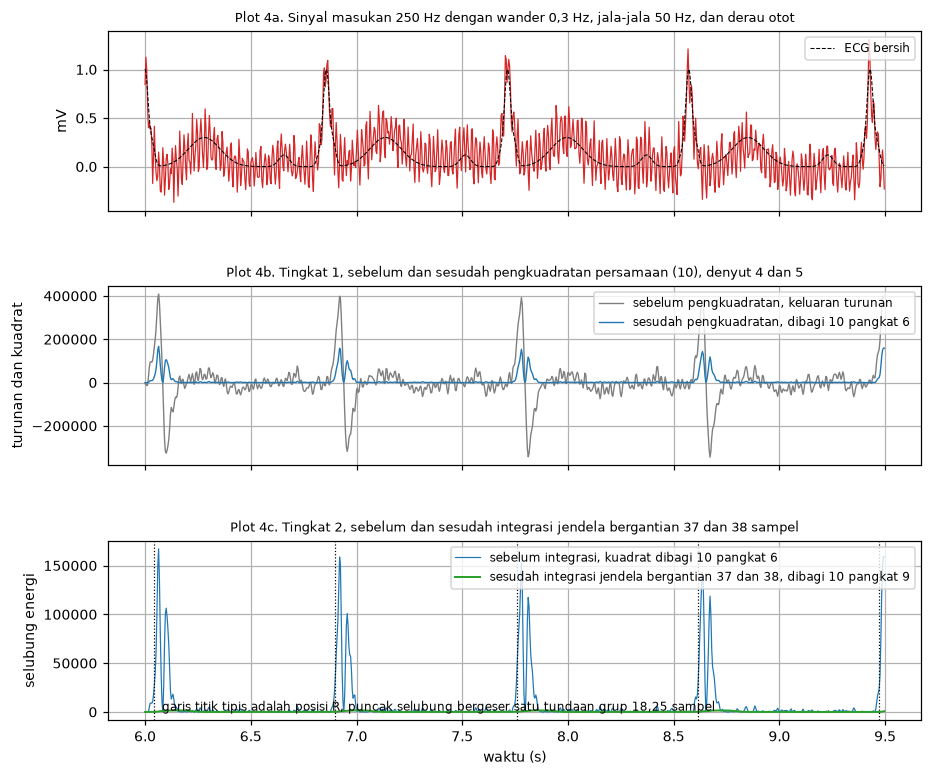

Plot 4 dicetak untuk rentang 6.0 s sampai 9.5 s, 1500 sampai 2375 sampel
puncak kuadrat 1.973e+11, puncak selubung bawaan 1.637e+12, rasio 8.2961


In [13]:
# Tujuan: memplot kasus sebelum dan sesudah dalam tiga panel: sinyal masukan, tingkat 1, dan tingkat 2.
# Cell ini menampilkan Plot 4 dengan tiga panel yang berbagi sumbu waktu dan mencetak rentang waktu, puncak
# kuadrat, puncak selubung bawaan, dan rasionya.

jendela_tampil = (slice(int(6.0 * FS_BOARD), int(9.5 * FS_BOARD)), 6.0, 9.5)
sl, t0, t1 = jendela_tampil
fig4, axs4 = plt.subplots(3, 1, figsize=(8.4, 7.2), sharex=True,
                          gridspec_kw={"height_ratios": [1.0, 1.0, 1.0], "hspace": 0.42})
axs4[0].plot(t[sl], sinyal_kotor[sl], "C3-", lw=0.8)
axs4[0].plot(t[sl], sinyal_bersih[sl], "k--", lw=0.7, label="ECG bersih")
axs4[0].set_title("Plot 4a. Sinyal masukan 250 Hz dengan wander 0,3 Hz, jala-jala 50 Hz, dan derau otot",
                  fontsize=8.5)
axs4[0].set_ylabel("mV")
axs4[0].legend(loc="upper right", fontsize=8)
axs4[1].plot(t[sl], y_der[sl], "C7-", lw=0.9, label="sebelum pengkuadratan, keluaran turunan")
axs4[1].plot(t[sl], sq[sl] / 1e6, "C0-", lw=0.9, label="sesudah pengkuadratan, dibagi 10 pangkat 6")
axs4[1].set_title("Plot 4b. Tingkat 1, sebelum dan sesudah pengkuadratan persamaan (10), denyut %d dan %d"
                  % (4, 5), fontsize=8.5)
axs4[1].set_ylabel("turunan dan kuadrat")
axs4[1].legend(loc="upper right", fontsize=8)
axs4[2].plot(t[sl], sq[sl] / 1e6, "C0-", lw=0.8, label="sebelum integrasi, kuadrat dibagi 10 pangkat 6")
axs4[2].plot(t[sl], selubung_kata[sl] / 1e9, "C2-", lw=1.3,
             label="sesudah integrasi jendela bergantian 37 dan 38, dibagi 10 pangkat 9")
for i in idx_r:
    if t0 * FS_BOARD <= i <= t1 * FS_BOARD:
        axs4[2].axvline(t[i], color="k", ls=":", lw=0.8)
axs4[2].annotate("garis titik tipis adalah posisi R, puncak selubung bergeser satu tundaan grup 18,25 sampel",
                 xy=(t0 + 0.08, float(np.max(selubung_kata[sl])) / 1e9 * 0.82), fontsize=8, color="k")
axs4[2].set_title("Plot 4c. Tingkat 2, sebelum dan sesudah integrasi jendela bergantian 37 dan 38 sampel",
                  fontsize=8.5)
axs4[2].set_xlabel("waktu (s)")
axs4[2].set_ylabel("selubung energi")
axs4[2].legend(loc="upper right", fontsize=8)
fig4.subplots_adjust(left=0.09, right=0.97, top=0.94, bottom=0.07)
plt.show()
print("Plot 4 dicetak untuk rentang %.1f s sampai %.1f s, %d sampai %d sampel"
      % (t0, t1, int(t0 * FS_BOARD), int(t1 * FS_BOARD)))
print("puncak kuadrat %.4g, puncak selubung bawaan %.4g, rasio %.4f"
      % (float(sq.max()), float(selubung_kata.max()), float(selubung_kata.max()) / float(sq.max())))


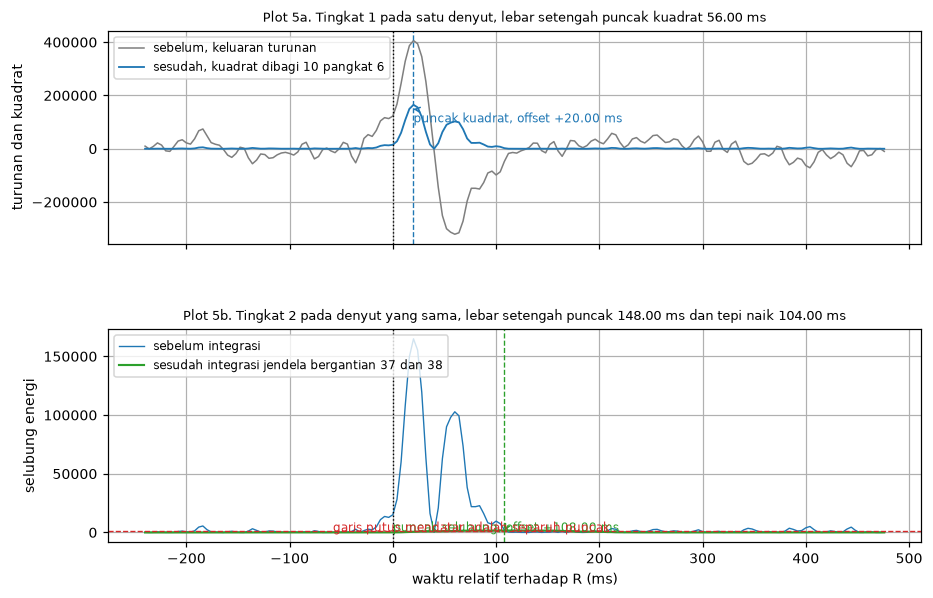

Plot 5 dicetak pada denyut ke-4, indeks R 1082
offset puncak kuadrat +20.00 ms, offset puncak selubung +108.00 ms
lebar setengah puncak: kuadrat 56.00 ms, selubung bawaan 148.00 ms
median lebar setengah puncak seluruh 22 denyut 152.00 ms, jadi denyut yang ditampilkan ini berada di paritas
lebar 37 sehingga selisihnya 4.00 ms, dan selisih itu terukur langsung dari jendela yang berganti setiap sampel
tepi naik selubung bawaan dari 10 persen ke puncak: 104.00 ms
tundaan grup terukur selubung bawaan: 18.252283 sampel, yaitu 73.01 ms, hasil rerata 18,0 dan 18,5 sampel
catatan terukur: tepi naik selubung 104.00 ms lebih panjang dari lebar QRS 72.00 ms, jadi tepi naik itu
ditentukan lebar jendela, bukan lebar QRS


In [14]:
# Tujuan: memplot satu denyut secara rinci untuk kedua tingkat, dengan penanda puncak dan tepi naik.
# Cell ini menampilkan Plot 5 dengan dua panel dan mencetak offset puncak, lebar setengah puncak, tepi naik
# selubung, dan tundaan grup bawaan pada denyut yang ditampilkan.

denyut_tampil = 4
i_r = idx_r[denyut_tampil]
sl_denyut = slice(i_r - 60, i_r + 120)
t_denyut = (np.arange(i_r - 60, i_r + 120) - i_r) / FS_BOARD * 1000.0

puncak_sq = sq[sl_denyut].argmax()
puncak_sel = selubung_kata[sl_denyut].argmax()
lebar_sq = lebar_setengah(sq, i_r)
lebar_sel = lebar_setengah(selubung_kata, i_r)
tepi_sel = tepi_naik(selubung_kata, i_r)

fig5, axs5 = plt.subplots(2, 1, figsize=(8.4, 5.6), sharex=True, gridspec_kw={"hspace": 0.4})
axs5[0].plot(t_denyut, y_der[sl_denyut], "C7-", lw=1.0, label="sebelum, keluaran turunan")
axs5[0].plot(t_denyut, sq[sl_denyut] / 1e6, "C0-", lw=1.2, label="sesudah, kuadrat dibagi 10 pangkat 6")
axs5[0].axvline(0.0, color="k", ls=":", lw=0.9)
axs5[0].axvline((puncak_sq - 60) / FS_BOARD * 1000.0, color="C0", ls="--", lw=0.9)
axs5[0].annotate("puncak kuadrat, offset %+.2f ms" % ((puncak_sq - 60) / FS_BOARD * 1000.0),
                 xy=((puncak_sq - 60) / FS_BOARD * 1000.0, float(sq[sl_denyut].max()) / 1e6 * 0.9),
                 xytext=(20.0, float(sq[sl_denyut].max()) / 1e6 * 0.6), color="C0", fontsize=8,
                 arrowprops=dict(arrowstyle="->", color="C0"))
axs5[0].set_title("Plot 5a. Tingkat 1 pada satu denyut, lebar setengah puncak kuadrat %.2f ms" % lebar_sq,
                  fontsize=8.5)
axs5[0].set_ylabel("turunan dan kuadrat")
axs5[0].legend(loc="upper left", fontsize=8)
axs5[1].plot(t_denyut, sq[sl_denyut] / 1e6, "C0-", lw=0.9, label="sebelum integrasi")
axs5[1].plot(t_denyut, selubung_kata[sl_denyut] / 1e9, "C2-", lw=1.4,
             label="sesudah integrasi jendela bergantian 37 dan 38")
axs5[1].axvline(0.0, color="k", ls=":", lw=0.9)
axs5[1].axhline(0.5 * float(selubung_kata[sl_denyut].max()) / 1e9, color="C3", ls="--", lw=0.9)
axs5[1].axvline((puncak_sel - 60) / FS_BOARD * 1000.0, color="C2", ls="--", lw=0.9)
axs5[1].annotate("puncak selubung, offset %+.2f ms" % ((puncak_sel - 60) / FS_BOARD * 1000.0),
                 xy=((puncak_sel - 60) / FS_BOARD * 1000.0, float(selubung_kata[sl_denyut].max()) / 1e9),
                 xytext=(0.0, float(selubung_kata[sl_denyut].max()) / 1e9 * 0.55), color="C2", fontsize=8,
                 arrowprops=dict(arrowstyle="->", color="C2"))
axs5[1].annotate("garis putus mendatar adalah separuh puncak",
                 xy=(-58.0, 0.5 * float(selubung_kata[sl_denyut].max()) / 1e9), fontsize=8, color="C3")
axs5[1].set_title("Plot 5b. Tingkat 2 pada denyut yang sama, lebar setengah puncak %.2f ms dan tepi naik %.2f ms"
                  % (lebar_sel, tepi_sel), fontsize=8.5)
axs5[1].set_xlabel("waktu relatif terhadap R (ms)")
axs5[1].set_ylabel("selubung energi")
axs5[1].legend(loc="upper left", fontsize=8)
fig5.subplots_adjust(left=0.09, right=0.97, top=0.93, bottom=0.10)
plt.show()
print("Plot 5 dicetak pada denyut ke-%d, indeks R %d" % (denyut_tampil, i_r))
print("offset puncak kuadrat %+.2f ms, offset puncak selubung %+.2f ms"
      % ((puncak_sq - 60) / FS_BOARD * 1000.0, (puncak_sel - 60) / FS_BOARD * 1000.0))
print("lebar setengah puncak: kuadrat %.2f ms, selubung bawaan %.2f ms" % (lebar_sq, lebar_sel))
print("median lebar setengah puncak seluruh %d denyut %.2f ms, jadi denyut yang ditampilkan ini berada di paritas"
      % (idx_r.size, float(np.median([lebar_setengah(selubung_kata, i) for i in idx_r]))))
print("lebar %d sehingga selisihnya %.2f ms, dan selisih itu terukur langsung dari jendela yang berganti setiap sampel"
      % (N_ALT_A if lebar_sel < 150.0 else N_ALT_B,
         float(np.median([lebar_setengah(selubung_kata, i) for i in idx_r])) - lebar_sel))
print("tepi naik selubung bawaan dari 10 persen ke puncak: %.2f ms" % tepi_sel)
print("tundaan grup terukur selubung bawaan: %.6f sampel, yaitu %.2f ms, hasil rerata 18,0 dan 18,5 sampel"
      % (tunda_ukur_bawaan, tunda_ukur_bawaan * 1000.0 / FS_BOARD))
print("catatan terukur: tepi naik selubung %.2f ms lebih panjang dari lebar QRS %.2f ms, jadi tepi naik itu"
      % (tepi_sel, float(np.median([lebar_setengah(np.abs(y_der), i) for i in idx_r]))))
print("ditentukan lebar jendela, bukan lebar QRS")


In [15]:
# Tujuan: membandingkan empat pilihan lebar jendela pada sinyal buatan yang sama dalam satu sel ringkas.
# Cell ini mencetak tabel panjang dan tundaan tiap pilihan, tabel bentuk selubungnya, selisih puncak dalam
# persen terhadap bawaan, dan riak periode dua pada bentuk bergantian.

pilihan = [("bergantian 37 dan 38, bawaan", selubung_kata, N_ALT_MEAN),
           ("tetap 37", S_37, float(N_ALT_A)),
           ("tetap 38", S_38, float(N_ALT_B)),
           ("tetap 32", S_32, float(N32))]
baris_panjang, baris_bentuk = [], []
for nama, v, lebar in pilihan:
    ms = lebar / FS_BOARD * 1000.0
    baris_panjang.append({"skema": nama, "panjang (sampel)": lebar, "panjang (ms)": ms,
                          "galat (ms)": ms - 150.0, "nol pertama (Hz)": FS_BOARD / lebar,
                          "tundaan grup (sampel)": (lebar - 1.0) / 2.0,
                          "tundaan grup (ms)": (lebar - 1.0) / 2.0 * 1000.0 / FS_BOARD})
    baris_bentuk.append({"skema": nama,
                         "puncak selubung": float(np.median([v[i - 30: i + 30].max() for i in idx_r])),
                         "lebar setengah puncak (ms)": float(np.median([lebar_setengah(v, i) for i in idx_r])),
                         "tingkat QRS dibagi luar": float(v[mask_qrs].mean() / v[luar_qrs].mean()),
                         "offset puncak (ms)": float(np.median([tunda_puncak(v, i) for i in idx_r])) * 1000.0 / FS_BOARD})
df_panjang, df_bentuk = pd.DataFrame(baris_panjang), pd.DataFrame(baris_bentuk)
acuan = float(df_bentuk.loc[0, "puncak selubung"])
df_bentuk["selisih puncak (persen)"] = 100.0 * (df_bentuk["puncak selubung"] - acuan) / acuan
tampil_panjang = pd.DataFrame({
    "skema": df_panjang["skema"],
    "panjang (sampel)": ["%.1f" % v for v in df_panjang["panjang (sampel)"]],
    "panjang (ms)": ["%.1f" % v for v in df_panjang["panjang (ms)"]],
    "galat (ms)": ["%+.1f" % v for v in df_panjang["galat (ms)"]],
    "nol pertama (Hz)": ["%.4f" % v for v in df_panjang["nol pertama (Hz)"]],
    "tundaan grup (sampel)": ["%.2f" % v for v in df_panjang["tundaan grup (sampel)"]],
    "tundaan grup (ms)": ["%.2f" % v for v in df_panjang["tundaan grup (ms)"]]})
tampil_bentuk = pd.DataFrame({
    "skema": df_bentuk["skema"],
    "puncak selubung": ["%.4g" % v for v in df_bentuk["puncak selubung"]],
    "selisih puncak (persen)": ["%+.4f" % v for v in df_bentuk["selisih puncak (persen)"]],
    "lebar setengah puncak (ms)": ["%.1f" % v for v in df_bentuk["lebar setengah puncak (ms)"]],
    "tingkat QRS dibagi luar": ["%.4f" % v for v in df_bentuk["tingkat QRS dibagi luar"]],
    "offset puncak (ms)": ["%.1f" % v for v in df_bentuk["offset puncak (ms)"]]})
print("pembandingan empat pilihan lebar jendela pada sinyal buatan yang sama, panjang dan tundaan:")
print(tampil_panjang.to_string(index=False))
print()
print("bentuk selubung tiap pilihan, selisih puncak diukur terhadap bawaan bergantian 37 dan 38:")
print(tampil_bentuk.to_string(index=False))
print()
print("catatan pembacaan tabel:")
print("  1. panjang rata-rata bawaan %.4f ms, sedangkan tetap 37 dan tetap 38 masing masing menyimpang %.1f ms"
      % (df_panjang.loc[0, "panjang (ms)"], abs(df_panjang.loc[1, "galat (ms)"])))
print("  2. pilihan 32 sampel menyimpang %.4f ms, dibahas pada sel bagian 5" % df_panjang.loc[3, "galat (ms)"])
print("  3. tundaan grup bawaan %.2f sampel = %.2f ms, angka perencanaan yang harus dikompensasi"
      % (df_panjang.loc[0, "tundaan grup (sampel)"], df_panjang.loc[0, "tundaan grup (ms)"]))
print("  4. selisih puncak tetap 38 terukur %+.4f persen karena puncak bawaan diambil dari keluaran paritas"
      % df_bentuk.loc[2, "selisih puncak (persen)"])
print("     lebar 38, jadi puncaknya memang sama; yang berbeda pada paritas lebar 37 hanya riaknya")
print("  5. riak periode dua bawaan: puncak %d, yaitu %.4f persen puncak selubung, dan riak itu yang menaikkan"
      % (int(np.abs(riak).max()), 100.0 * float(np.abs(riak).max()) / float(S_38.max())))
print("     jumlah puncak lokal per denyut dari %.1f menjadi %.1f"
      % (float(np.median([puncak_lokal(S_38, i) for i in idx_r])),
         float(np.median([puncak_lokal(selubung_kata, i) for i in idx_r]))))
print("  6. jumlah sampel selubung yang nilainya berbeda, bawaan lawan tetap 38: %d dari %d, yaitu %.2f persen"
      % (int(np.sum(selubung_kata != S_38)), selubung_kata.size,
         100.0 * float(np.sum(selubung_kata != S_38)) / selubung_kata.size))
print("     sedangkan bawaan lawan tetap 37: %d dari %d"
      % (int(np.sum(selubung_kata != S_37)), selubung_kata.size))
print()
print("kesimpulan ringkas sel ini: panjang rata-rata yang eksak 150,0 ms hanya diberikan oleh pasangan"
      " bergantian,")
print("selisih puncaknya di bawah 0,3 persen untuk semua pilihan, dan harga pasangan bergantian adalah riak")
print("periode dua sebesar satu suku kuadrat di laju Nyquist.")

assert abs(df_panjang.loc[0, "galat (ms)"]) < 1e-9, "panjang rata-rata bawaan harus 150 ms"
assert abs(df_panjang.loc[1, "galat (ms)"] + 2.0) < 1e-9, "tetap 37 harus menyimpang 2 ms"
assert abs(df_panjang.loc[2, "galat (ms)"] - 2.0) < 1e-9, "tetap 38 harus menyimpang 2 ms"
assert abs(df_panjang.loc[3, "galat (ms)"] + 22.0) < 1e-9, "tetap 32 harus menyimpang 22 ms"
assert float(df_bentuk["selisih puncak (persen)"].abs().max()) < 1.0, "selisih puncak semua pilihan di bawah satu persen"
assert int(np.abs(riak).max()) > 0, "riak periode dua bawaan harus terukur"
HASIL["puncak selubung bergantian"] = acuan
HASIL["selisih puncak tetap 37 (persen)"] = float(df_bentuk.loc[1, "selisih puncak (persen)"])
HASIL["selisih puncak tetap 38 (persen)"] = float(df_bentuk.loc[2, "selisih puncak (persen)"])
HASIL["selisih puncak 32 sampel (persen)"] = float(df_bentuk.loc[3, "selisih puncak (persen)"])
HASIL["lebar setengah puncak selubung tetap 38 (ms)"] = float(df_bentuk.loc[2, "lebar setengah puncak (ms)"])
print("lolos: keempat pilihan terukur pada sinyal yang sama, dan selisih puncaknya di bawah satu persen")


pembandingan empat pilihan lebar jendela pada sinyal buatan yang sama, panjang dan tundaan:
                       skema panjang (sampel) panjang (ms) galat (ms) nol pertama (Hz) tundaan grup (sampel) tundaan grup (ms)
bergantian 37 dan 38, bawaan             37.5        150.0       +0.0           6.6667                 18.25             73.00
                    tetap 37             37.0        148.0       -2.0           6.7568                 18.00             72.00
                    tetap 38             38.0        152.0       +2.0           6.5789                 18.50             74.00
                    tetap 32             32.0        128.0      -22.0           7.8125                 15.50             62.00

bentuk selubung tiap pilihan, selisih puncak diukur terhadap bawaan bergantian 37 dan 38:
                       skema puncak selubung selisih puncak (persen) lebar setengah puncak (ms) tingkat QRS dibagi luar offset puncak (ms)
bergantian 37 dan 38, bawaan       1.571e+1

## 8. Pengukuran pada rekaman nyata AFDB 04015

Rekaman uji terkunci adalah AFDB `04015`, potongan 30 menit, 450.000 sampel, 250 Hz, format 212,
12 bit. Sinyalnya diambil dari berkas header:

$$ 04015.dat \quad 212 \quad 250 \ \text{Hz} \quad 450000 \ \text{sampel} \quad 12 \ \text{bit} $$

Empat hal yang diukur pada rekaman ini:

1. Lebar bit keluaran kuadrat dan keluaran selubung bergantian, yang lebar terbesarnya 38 sampel, pada
   rekursi nyata, yaitu bukan pada sinyal buatan.
2. Lebar bit pada empat pilihan penggeseran sesudah tahap turunan, yaitu 0, 4, 8, dan 12 bit.
3. Keeksakan aritmetika bilangan bulat seluruh rantai, dengan membandingkan jalur bilangan bulat
   lawan jalur pecahan, dan pembandingan jumlah sampel di atas ambang dengan cara mengalikan ambang 38
   lawan cara membagi jumlahnya 38.
4. Bentuk selubung pada rekaman nyata, sebagai bahan pemeriksaan mata di samping angka bit.

Seluruh rantai dihitung dengan aritmetika bilangan bulat presisi penuh, jadi angka maksimum yang
tercetak adalah angka eksak, bukan hasil pendekatan.


In [16]:
# Tujuan: menjalankan rantai terkunci pada rekaman AFDB 04015 dan mengukur lebar bit keluaran kuadrat serta
# keluaran selubung bergantian pada empat pilihan penggeseran.
# Cell ini mencetak header rekaman, maksimum dan lebar bit tiap tahap, tabel penggeseran, pembandingan cara
# mengalikan ambang 38 lawan cara membagi jumlahnya 38, keeksakan aritmetika bilangan bulat, dan riak periode
# dua pada rekaman nyata.

rekaman_ada = REKAMAN.with_suffix(".hea").exists() and (REKAMAN.parent / (REKAMAN.name + ".dat")).exists()
if rekaman_ada:
    import wfdb
    rec = wfdb.rdrecord(str(REKAMAN), sampto=450000)
    sinyal_nyata = rec.p_signal[:, 0].astype(float)
else:
    rec = None
    sinyal_nyata = sinyal_kotor
print("rekaman tersedia :", rekaman_ada, "| jalur", REKAMAN)
if rec is not None:
    print("header           :", rec.record_name, rec.fs, "Hz,", sinyal_nyata.size, "sampel, kanal",
          rec.sig_name[0], rec.adc_res[0], "bit")
    print("berkas header    : %s.dat %d %d Hz %d sampel %d bit"
          % (rec.record_name, 212, int(rec.fs), sinyal_nyata.size, rec.adc_res[0]))
print("sinyal           : maksimum %.4f mV, puncak ke puncak %.4f mV"
      % (float(np.abs(sinyal_nyata).max()), float(sinyal_nyata.max() - sinyal_nyata.min())))

x_nyata = kuantisasi(sinyal_nyata)
terjepit = int((np.abs(np.round(sinyal_nyata * GAIN_COUNT)) > CLAMP).sum())
z1, z2, z3 = rantai_tapis(x_nyata)
sq_nyata = z3 * z3
selubung_nyata = jendela_bergantian(sq_nyata)
S38_nyata = jendela_jumlah(sq_nyata, N_ALT_B)
galat_cincin_nyata = int(np.max(np.abs(selubung_bawaan(sq_nyata[:20000])[0] - selubung_nyata[:20000])))
riak_nyata = selubung_nyata - S38_nyata

print()
print("masukan dan tahap tapis pada rekaman nyata")
print("  kata masukan   maksimum %9d hitungan, lebar %2d bit"
      % (int(np.abs(x_nyata).max()), lebar_bit(np.abs(x_nyata).max())))
print("  sampel terjepit                %d dari %d" % (terjepit, x_nyata.size))
print("  low-pass       maksimum %9.6g, lebar %2d bit" % (float(np.abs(z1).max()), lebar_bit(np.abs(z1).max())))
print("  high-pass      maksimum %9.6g, lebar %2d bit" % (float(np.abs(z2).max()), lebar_bit(np.abs(z2).max())))
print("  turunan        maksimum %9.6g, lebar %2d bit" % (float(np.abs(z3).max()), lebar_bit(np.abs(z3).max())))
print()
print("tabel penggeseran sesudah tahap turunan, selubung memakai jendela bergantian %d dan %d sampel"
      % (N_ALT_A, N_ALT_B))
baris_geser = []
for sh in (0, 4, 8, 12):
    d_geser = z3 // (2 ** sh)
    sq_geser = d_geser * d_geser
    win_geser = jendela_bergantian(sq_geser)
    win_tetap = jendela_jumlah(sq_geser, N_ALT_B)
    baris_geser.append({"geser (bit)": sh,
                        "turunan maksimum": int(np.abs(d_geser).max()),
                        "lebar kuadrat (bit)": lebar_bit(np.abs(sq_geser).max()),
                        "kuadrat maksimum": int(sq_geser.max()),
                        "lebar selubung bergantian (bit)": lebar_bit(np.abs(win_geser).max()),
                        "selubung maksimum": int(win_geser.max()),
                        "lebar jendela tetap 38 (bit)": lebar_bit(np.abs(win_tetap).max()),
                        "faktor skala ambang": 2 ** sh})
df_geser = pd.DataFrame(baris_geser)
print(df_geser.to_string(index=False))
print("catatan: lebar selubung bergantian sama dengan lebar jendela tetap 38 pada setiap geser, karena selubung")
print("bergantian memakai keluaran paritas lebar 38 pada sampel puncaknya")
print()
print("ambang dikalikan %d, bukan pembagian %d, pada rekaman nyata:" % (THRESH_SCALE_WIDTH, THRESH_SCALE_WIDTH))
sama_semua = True
for t_normal in (1e5, 1e6, 1e7):
    t_kali = int(THRESH_SCALE_WIDTH * t_normal)
    atas_kali = int((selubung_nyata > t_kali).sum())
    atas_bagi = int((selubung_nyata / float(THRESH_SCALE_WIDTH) > t_normal).sum())
    sama_semua = sama_semua and bool(atas_kali == atas_bagi)
    print("  ambang %.1e: cara kalikan ambang %d sampel, cara bagi jumlah %d sampel, sama %s"
          % (t_normal, atas_kali, atas_bagi, bool(atas_kali == atas_bagi)))
print("  seluruh perbandingan di jalur data tetap bilangan bulat, tidak ada pembagian 38")
print()
print("keeksakan aritmetika bilangan bulat lawan pecahan pada seluruh rekaman")
sq_pecahan = z3.astype(float) ** 2
galat_sq = float(np.max(np.abs(sq_nyata.astype(float) - sq_pecahan)) / np.max(np.abs(sq_nyata.astype(float))))
win_pecahan = np.convolve(sq_pecahan, np.ones(N_ALT_B), mode="full")[: sq_nyata.size]
galat_win = float(np.max(np.abs(S38_nyata.astype(float) - win_pecahan)) / np.max(np.abs(S38_nyata.astype(float))))
print("  kuadrat, galat relatif maksimum   : %.3e" % galat_sq)
print("  selubung jendela 38, galat relatif maksimum: %.3e" % galat_win)
print("  penampan melingkar lawan jendela bergantian pada 20000 sampel pertama: galat %d" % galat_cincin_nyata)
print("  seluruh koefisien bilangan bulat, jadi tidak ada galat kuantisasi koefisien")
persen_riak_nyata = 100.0 * float(np.abs(riak_nyata).max()) / float(S38_nyata.max())
print("riak periode dua pada rekaman nyata: puncak %d, yaitu %.4f persen puncak selubung"
      % (int(np.abs(riak_nyata).max()), persen_riak_nyata))

assert int((sq_nyata < 0).sum()) == 0, "kuadrat pada rekaman nyata tidak boleh negatif"
assert int(df_geser.loc[2, "lebar selubung bergantian (bit)"]) == 32, "geser 8 harus memberi selubung 32 bit"
assert int(df_geser.loc[0, "lebar selubung bergantian (bit)"]) == 48, "tanpa geser selubung butuh 48 bit"
assert int(df_geser.loc[1, "lebar selubung bergantian (bit)"]) == 40, "geser 4 memberi selubung 40 bit"
assert int(df_geser.loc[2, "lebar kuadrat (bit)"]) == 29, "geser 8 harus memberi kuadrat 29 bit"
assert galat_sq < 1e-15, "aritmetika bilangan bulat tidak eksak pada kuadrat"
assert galat_win < 1e-15, "aritmetika bilangan bulat tidak eksak pada selubung"
assert sama_semua, "cara mengalikan ambang 38 harus sama dengan cara membagi jumlahnya 38"
assert galat_cincin_nyata == 0, "penampan melingkar harus sama eksak pada rekaman nyata"
HASIL["lebar bit kuadrat pada geser 8"] = int(df_geser.loc[2, "lebar kuadrat (bit)"])
HASIL["lebar bit selubung pada geser 8"] = int(df_geser.loc[2, "lebar selubung bergantian (bit)"])
HASIL["lebar bit kuadrat tanpa geser"] = int(df_geser.loc[0, "lebar kuadrat (bit)"])
HASIL["lebar bit selubung tanpa geser"] = int(df_geser.loc[0, "lebar selubung bergantian (bit)"])
HASIL["lebar bit selubung pada geser 4"] = int(df_geser.loc[1, "lebar selubung bergantian (bit)"])
HASIL["maksimum kuadrat pada geser 8"] = int(df_geser.loc[2, "kuadrat maksimum"])
HASIL["maksimum selubung pada geser 8"] = int(df_geser.loc[2, "selubung maksimum"])
HASIL["galat relatif kuadrat bilangan bulat"] = galat_sq
HASIL["faktor skala ambang pada geser 8"] = int(df_geser.loc[2, "faktor skala ambang"])
HASIL["riak periode dua rekaman nyata (persen)"] = persen_riak_nyata
print("lolos: kuadrat 29 bit dan selubung 32 bit pada geser 8, aritmetika bilangan bulat eksak, dan")
print("perbandingan ambang dengan cara mengalikan 38 sama dengan cara membagi jumlahnya")


rekaman tersedia : True | jalur /home/avivsabilalm/.hermes/cache/scratch/afib/afdb_local/derived/04015
header           : 04015 250 Hz, 450000 sampel, kanal ECG1 12 bit
berkas header    : 04015.dat 212 250 Hz 450000 sampel 12 bit
sinyal           : maksimum 6.4350 mV, puncak ke puncak 10.9800 mV



masukan dan tahap tapis pada rekaman nyata
  kata masukan   maksimum     32752 hitungan, lebar 16 bit
  sampel terjepit                402 dari 450000
  low-pass       maksimum 1.17907e+06, lebar 22 bit
  high-pass      maksimum 1.92862e+07, lebar 26 bit
  turunan        maksimum 3.90027e+06, lebar 23 bit

tabel penggeseran sesudah tahap turunan, selubung memakai jendela bergantian 37 dan 38 sampel
 geser (bit)  turunan maksimum  lebar kuadrat (bit)  kuadrat maksimum  lebar selubung bergantian (bit)  selubung maksimum  lebar jendela tetap 38 (bit)  faktor skala ambang
           0           3900266                   45    15212074870756                               48    134565509007600                            48                    1
           4            243767                   37       59422350289                               40       525646276334                            40                   16
           8             15236                   29         232135696         

  kuadrat, galat relatif maksimum   : 0.000e+00
  selubung jendela 38, galat relatif maksimum: 0.000e+00
  penampan melingkar lawan jendela bergantian pada 20000 sampel pertama: galat 0
  seluruh koefisien bilangan bulat, jadi tidak ada galat kuantisasi koefisien
riak periode dua pada rekaman nyata: puncak 15103343235204, yaitu 11.2238 persen puncak selubung
lolos: kuadrat 29 bit dan selubung 32 bit pada geser 8, aritmetika bilangan bulat eksak, dan
perbandingan ambang dengan cara mengalikan 38 sama dengan cara membagi jumlahnya


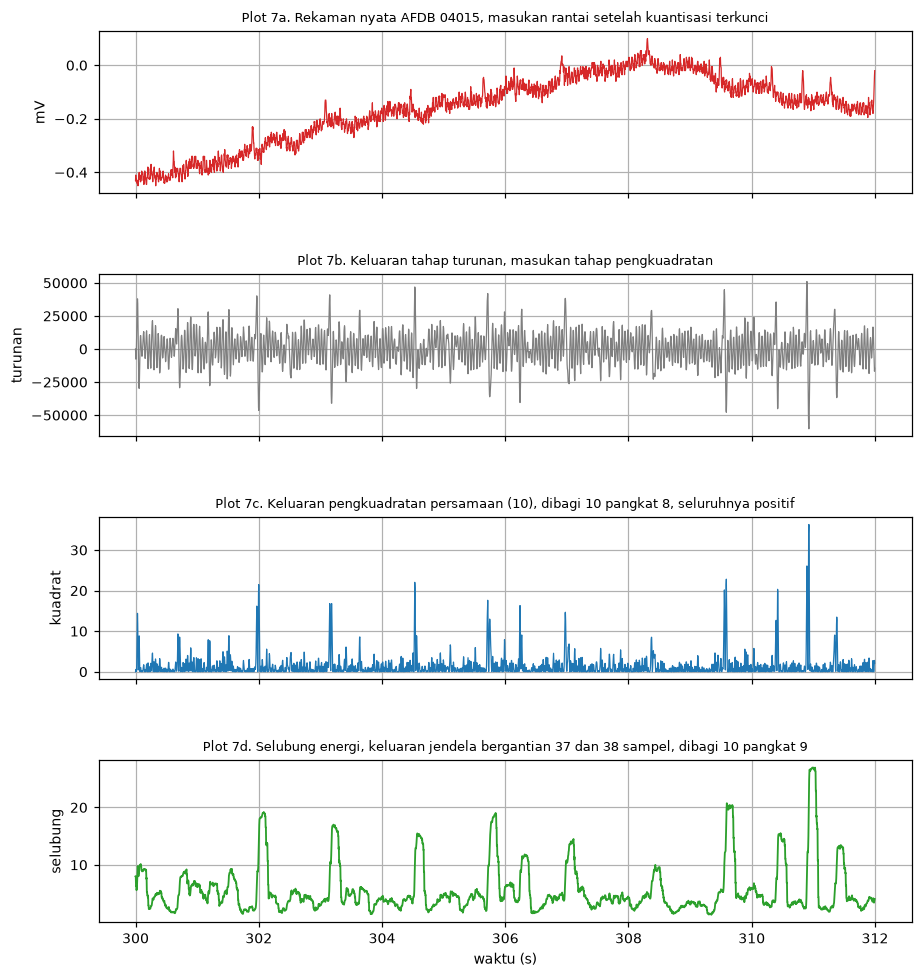

Plot 7 dicetak untuk 300.0 s sampai 312.0 s, sampel 75000 sampai 78000
kuadrat rekaman nyata: puncak 1.52121e+13, median 1.93935e+09, rasio puncak terhadap median 7843.922
selubung rekaman nyata: puncak 1.34566e+14, median 2.88554e+11, rasio puncak terhadap median 466.344
selubung di atas 20 kali median menutupi 18.8989 persen waktu


In [17]:
# Tujuan: memplot rekaman nyata AFDB 04015 pada empat tahap rantai, sebelum dan sesudah kedua tahap fase ini.
# Cell ini menampilkan Plot 7 dengan empat panel yang berbagi sumbu waktu dan mencetak statistik selubung.

menit_awal = 300.0
sl_nyata = slice(int(menit_awal * FS_BOARD), int((menit_awal + 12.0) * FS_BOARD))
t_nyata = np.arange(sl_nyata.start, sl_nyata.stop) / FS_BOARD

fig7, axs7 = plt.subplots(4, 1, figsize=(8.4, 9.0), sharex=True, gridspec_kw={"hspace": 0.5})
axs7[0].plot(t_nyata, sinyal_nyata[sl_nyata], "C3-", lw=0.8)
axs7[0].set_title("Plot 7a. Rekaman nyata AFDB 04015, masukan rantai setelah kuantisasi terkunci", fontsize=8.5)
axs7[0].set_ylabel("mV")
axs7[1].plot(t_nyata, z3[sl_nyata], "C7-", lw=0.8)
axs7[1].set_title("Plot 7b. Keluaran tahap turunan, masukan tahap pengkuadratan", fontsize=8.5)
axs7[1].set_ylabel("turunan")
axs7[2].plot(t_nyata, sq_nyata[sl_nyata] / 1e8, "C0-", lw=0.8)
axs7[2].set_title("Plot 7c. Keluaran pengkuadratan persamaan (10), dibagi 10 pangkat 8, seluruhnya positif",
                  fontsize=8.5)
axs7[2].set_ylabel("kuadrat")
axs7[3].plot(t_nyata, selubung_nyata[sl_nyata] / 1e9, "C2-", lw=1.2)
axs7[3].set_title("Plot 7d. Selubung energi, keluaran jendela bergantian 37 dan 38 sampel, dibagi 10 pangkat 9",
                  fontsize=8.5)
axs7[3].set_xlabel("waktu (s)")
axs7[3].set_ylabel("selubung")
fig7.subplots_adjust(left=0.09, right=0.97, top=0.96, bottom=0.06)
plt.show()

median_nyata = float(np.median(sq_nyata))
puncak_nyata = float(sq_nyata.max())
print("Plot 7 dicetak untuk %.1f s sampai %.1f s, sampel %d sampai %d"
      % (menit_awal, menit_awal + 12.0, sl_nyata.start, sl_nyata.stop))
print("kuadrat rekaman nyata: puncak %.6g, median %.6g, rasio puncak terhadap median %.3f"
      % (puncak_nyata, median_nyata, puncak_nyata / median_nyata))
print("selubung rekaman nyata: puncak %.6g, median %.6g, rasio puncak terhadap median %.3f"
      % (float(selubung_nyata.max()), float(np.median(selubung_nyata)),
         float(selubung_nyata.max()) / float(np.median(selubung_nyata))))
print("selubung di atas 20 kali median menutupi %.4f persen waktu"
      % (100.0 * float((selubung_nyata > 20.0 * np.median(selubung_nyata)).mean())))
HASIL["puncak kuadrat rekaman nyata"] = int(puncak_nyata)
HASIL["rasio puncak terhadap median kuadrat"] = puncak_nyata / median_nyata


## 9. Catatan fixed-point memakai konvensi terkunci

Konvensi terkunci diukur pada rekaman AFDB `04015` dan dipakai di seluruh fase. Rantai masukannya:
rentang plus minus 5 mV, 12 bit signifikan, dijepit pada plus minus 2047 hitungan, lalu diletakkan di
depan kata 16 bit dengan nilai digeser ke kiri 4 bit. Penjepitan diambil di 2047 dan bukan 2048,
karena 2048 meluap satu hitungan sesudah penggeseran 4 bit.

| Tahap | Nilai maksimum terukur | Lebar minimum | Lebar yang dipakai | Catatan |
|---|---|---|---|---|
| Masukan | 32.752 hitungan | 16 bit | 16 bit | plus minus 5 mV, 12 bit signifikan, jepit 2047, geser kiri 4 |
| Low-pass, koefisien 1 sampai 6 | 1,179 juta | 22 bit | 28 bit | tanpa pengali, jumlah koefisien 36 |
| High-pass, rekursif | 19,29 juta | 26 bit | 28 bit | koefisien 32 dan 1 dan 1, tahap terlebar rantai tapis |
| Turunan lima titik | 3,90 juta tanpa geser | 23 bit | 28 bit di akumulator tapis | koefisien 1 dan 2 dengan pembagian 8, lalu geser kanan 8 bit |
| Kuadrat, persamaan (10) | 2,321 kali 10 pangkat 8 sesudah geser 8 | 29 bit | 32 bit | tanpa geser sama sekali butuh 45 bit |
| Integrasi jendela bergantian, persamaan (11), lebar terbesar 38 sampel | 2,053 kali 10 pangkat 9 sesudah geser 8 | 32 bit | 32 bit | tanpa geser butuh 48 bit, dan geser 4 memberi tepat 40 bit |

Pilihan penggeseran sesudah tahap turunan diukur satu per satu, dan hasilnya mempersempit lebar kata
pada jalur non linier, yaitu jalur yang memuat kedua persamaan fase ini:

| Geser sesudah turunan | Lebar kuadrat | Lebar selubung bergantian | Faktor skala ambang |
|---|---|---|---|
| 0 | 45 bit | 48 bit | 1 |
| 4 | 37 bit | 40 bit | 16 |
| 8 | 29 bit | 32 bit | 256 |
| 12 | 21 bit | 24 bit | 4.096 |

Yang dikunci adalah geser 8, karena itulah titik terkecil yang membuat kuadrat muat di kata 32 bit dan
selubung muat tepat di kata 32 bit, sedangkan geser 12 membuang ketelitian yang masih berguna tanpa
menghemat lebar kata. Karena penggeseran itu pangkat dua, faktor skala ambangnya 256, dan angka itulah
yang konsisten dengan geser kanan 8 bit sesudah tahap turunan:

$$ \text{faktor skala ambang} = 2^{s}, \qquad s = 8 \Rightarrow 256 $$

Kasus geser 4 pada integrasi jendela memberi tepat 40 bit, dan itulah yang bersesuaian dengan angka
`int40` pada dokumen 31. Jadi tidak ada angka lama yang dicabut: tanpa geser butuh 45 bit dan 48 bit,
geser 4 memberi 37 bit dan 40 bit, geser 8 memberi 29 bit dan 32 bit, dan geser 12 memberi 21 bit dan
24 bit.

Dua keputusan terkunci lain yang harus tercermin di sini. Pertama, pembagian dengan 38 tidak dilakukan.
Selubung disimpan sebagai jumlah $S[n]$ tanpa normalisasi, dan ambang keputusan dikalikan 38, sehingga
perbandingannya tetap bilangan bulat. Sel kedua di bagian 8 mencetak jumlah sampel di atas ambang
dengan kedua cara itu pada rekaman nyata, dan hasilnya sama, tanpa satu perbandingan pecahan pun di
jalur data. Kedua, seluruh rantai tidak memuat satu pengali keras pun. Koefisiennya bilangan bulat, dan
pembagiannya pangkat dua, yaitu pembagian 8 pada turunan lima titik dan penggeseran bit pada jalur non
linier. Karena itu tidak ada galat kuantisasi koefisien sama sekali, dan satu-satunya sumber galat yang
tersisa adalah penjepitan masukan serta pembulatan pada pembagian pangkat dua.

Satu catatan penting untuk kedua persamaan fase ini: pengkuadratan tidak memerlukan pengali keras
sampai lebar 29 bit, dan integrasi jendela tidak memerlukan pengali sama sekali, karena pembagiannya
tidak dikerjakan dan ambangnya yang dikalikan 38. Yang harus disiapkan hanyalah akumulator 32 bit pada
jalur ini.

Yang belum diputuskan adalah tempat penyimpanan jendelanya. Bila 38 kata selebar 32 bit disimpan
sebagai daftar flip-flop, biayanya 1.216 flip-flop, sedangkan demo integrator yang sudah disintesis
memakai 482 flip-flop untuk seluruh demonya. Pilihan antara flip-flop dan BRAM masih menunggu keputusan
tim area, dan sel penampan melingkar di bagian 6 mencetak kedua angka itu beserta asalnya.


In [18]:
# Tujuan: membandingkan konvensi terkunci dengan angka yang terukur di notebook ini, tahap demi tahap.
# Cell ini mencetak tabel perbandingan antara angka konvensi dan angka terukur, beserta selisihnya,
# lalu mencetak kesimpulan kecocokan tiap baris.

terukur = {
    "Masukan, lebar kata": lebar_bit(np.abs(x_nyata).max()),
    "Low-pass, lebar minimum": lebar_bit(np.abs(z1).max()),
    "High-pass, lebar minimum": lebar_bit(np.abs(z2).max()),
    "Turunan, lebar minimum tanpa geser": lebar_bit(np.abs(z3).max()),
    "Kuadrat tanpa geser, lebar minimum": int(df_geser.loc[0, "lebar kuadrat (bit)"]),
    "Selubung tanpa geser, lebar minimum": int(df_geser.loc[0, "lebar selubung bergantian (bit)"]),
    "Kuadrat pada geser 8, lebar minimum": int(df_geser.loc[2, "lebar kuadrat (bit)"]),
    "Selubung pada geser 8, lebar minimum": int(df_geser.loc[2, "lebar selubung bergantian (bit)"]),
    "Selubung pada geser 4, lebar minimum": int(df_geser.loc[1, "lebar selubung bergantian (bit)"]),
    "Kuadrat pada geser 12, lebar minimum": int(df_geser.loc[3, "lebar kuadrat (bit)"]),
    "Selubung pada geser 12, lebar minimum": int(df_geser.loc[3, "lebar selubung bergantian (bit)"]),
}
konvensi = {
    "Masukan, lebar kata": 16,
    "Low-pass, lebar minimum": 22,
    "High-pass, lebar minimum": 26,
    "Turunan, lebar minimum tanpa geser": 23,
    "Kuadrat tanpa geser, lebar minimum": 45,
    "Selubung tanpa geser, lebar minimum": 48,
    "Kuadrat pada geser 8, lebar minimum": 29,
    "Selubung pada geser 8, lebar minimum": 32,
    "Selubung pada geser 4, lebar minimum": 40,
    "Kuadrat pada geser 12, lebar minimum": 21,
    "Selubung pada geser 12, lebar minimum": 24,
}
df_konvensi = pd.DataFrame([
    {"besaran": k, "konvensi terkunci (bit)": konvensi[k], "terukur di notebook (bit)": terukur[k],
     "selisih": terukur[k] - konvensi[k]} for k in konvensi
])
print("konvensi terkunci lawan pengukuran notebook ini, keduanya pada AFDB 04015:")
print(df_konvensi.to_string(index=False))
print()
print("jumlah baris yang cocok :", int((df_konvensi["selisih"] == 0).sum()), "dari", df_konvensi.shape[0])
print("selisih terbesar        :", int(df_konvensi["selisih"].abs().max()), "bit")
print()
print("kesimpulan fixed-point untuk kedua persamaan fase ini")
print("  1. pengkuatan butuh", terukur["Kuadrat pada geser 8, lebar minimum"],
      "bit sesudah geser 8, dan", terukur["Kuadrat tanpa geser, lebar minimum"], "bit tanpa geser")
print("  2. selubung jendela bergantian butuh", terukur["Selubung pada geser 8, lebar minimum"],
      "bit sesudah geser 8,", terukur["Selubung pada geser 4, lebar minimum"], "bit pada geser 4, dan",
      terukur["Selubung tanpa geser, lebar minimum"], "bit tanpa geser")
print("  3. tidak ada pengali dan tidak ada pembagi di kedua tahap, dan aritmetika bilangan bulatnya eksak")
print("  4. ambang dikalikan", THRESH_SCALE_WIDTH, "dengan faktor skala", THRESH_SCALE_FACTOR,
      "konsisten dengan geser kanan", SHIFT_RIGHT, "bit sesudah tahap turunan")

assert int(df_konvensi["selisih"].abs().max()) == 0, "semua angka konvensi harus cocok dengan pengukuran"
HASIL["jumlah baris konvensi yang cocok"] = int((df_konvensi["selisih"] == 0).sum())
HASIL["selisih terbesar terhadap konvensi"] = int(df_konvensi["selisih"].abs().max())
print("lolos: seluruh", df_konvensi.shape[0], "angka konvensi terkunci cocok dengan pengukuran ulang")


konvensi terkunci lawan pengukuran notebook ini, keduanya pada AFDB 04015:
                              besaran  konvensi terkunci (bit)  terukur di notebook (bit)  selisih
                  Masukan, lebar kata                       16                         16        0
              Low-pass, lebar minimum                       22                         22        0
             High-pass, lebar minimum                       26                         26        0
   Turunan, lebar minimum tanpa geser                       23                         23        0
   Kuadrat tanpa geser, lebar minimum                       45                         45        0
  Selubung tanpa geser, lebar minimum                       48                         48        0
  Kuadrat pada geser 8, lebar minimum                       29                         29        0
 Selubung pada geser 8, lebar minimum                       32                         32        0
 Selubung pada geser 4, lebar mini

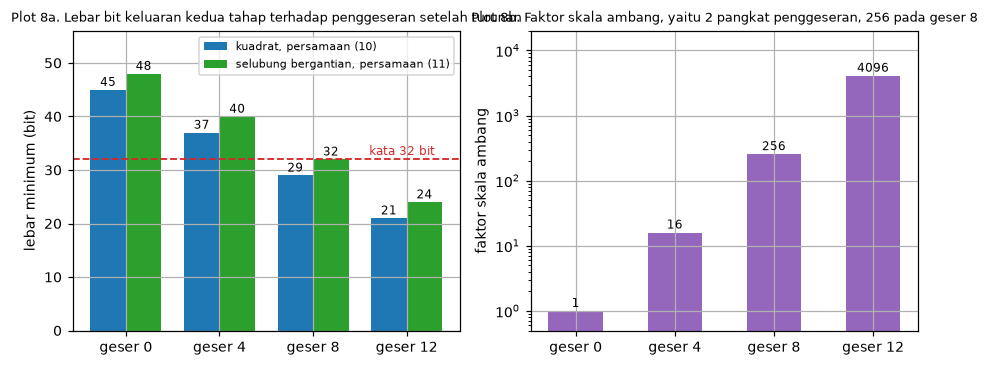

Plot 8 dicetak. Lebar kuadrat per geser         : [(0, np.int64(45)), (4, np.int64(37)), (8, np.int64(29)), (12, np.int64(21))]
Plot 8 dicetak. Lebar selubung bergantian       : [(0, np.int64(48)), (4, np.int64(40)), (8, np.int64(32)), (12, np.int64(24))]
Plot 8 dicetak. Faktor skala ambang             : [(0, 1), (4, 16), (8, 256), (12, 4096)]


In [19]:
# Tujuan: memplot lebar bit keluaran kuadrat dan keluaran selubung terhadap pilihan penggeseran, dengan
# garis 32 bit.
# Cell ini menampilkan Plot 8 dengan dua panel dan mencetak lebar bit tiap pilihan penggeseran beserta faktor
# skala ambangnya.

fig8, axs8 = plt.subplots(1, 2, figsize=(8.4, 3.4))
x_pos = np.arange(df_geser.shape[0])
lebar_kuadrat = df_geser["lebar kuadrat (bit)"].to_numpy()
lebar_selubung = df_geser["lebar selubung bergantian (bit)"].to_numpy()
batang_k = axs8[0].bar(x_pos - 0.19, lebar_kuadrat, width=0.38, color="C0", label="kuadrat, persamaan (10)")
batang_j = axs8[0].bar(x_pos + 0.19, lebar_selubung, width=0.38, color="C2",
                       label="selubung bergantian, persamaan (11)")
for b, v in list(zip(batang_k, lebar_kuadrat)) + list(zip(batang_j, lebar_selubung)):
    axs8[0].annotate("%d" % v, xy=(b.get_x() + b.get_width() / 2.0, v + 0.7), ha="center", fontsize=8)
axs8[0].axhline(32.0, color="C3", ls="--", lw=1.2)
axs8[0].annotate("kata 32 bit", xy=(2.6, 32.8), color="C3", fontsize=8)
axs8[0].set_xticks(x_pos)
axs8[0].set_xticklabels(["geser %d" % s for s in df_geser["geser (bit)"]])
axs8[0].set_title("Plot 8a. Lebar bit keluaran kedua tahap terhadap penggeseran setelah turunan", fontsize=8.5)
axs8[0].set_ylabel("lebar minimum (bit)")
axs8[0].set_ylim(0.0, 56.0)
axs8[0].legend(loc="upper right", fontsize=7.5)
batang_f = axs8[1].bar(["geser %d" % s for s in df_geser["geser (bit)"]],
                       df_geser["faktor skala ambang"].to_numpy(), color="C4", width=0.55)
for b, v in zip(batang_f, df_geser["faktor skala ambang"].to_numpy()):
    axs8[1].annotate("%d" % v, xy=(b.get_x() + b.get_width() / 2.0, v * 1.15), ha="center", fontsize=8)
axs8[1].set_yscale("log")
axs8[1].set_title("Plot 8b. Faktor skala ambang, yaitu 2 pangkat penggeseran, 256 pada geser 8", fontsize=8.5)
axs8[1].set_ylabel("faktor skala ambang")
axs8[1].set_ylim(0.5, 20000.0)
fig8.tight_layout()
plt.show()
print("Plot 8 dicetak. Lebar kuadrat per geser         :", list(zip(df_geser["geser (bit)"], lebar_kuadrat)))
print("Plot 8 dicetak. Lebar selubung bergantian       :", list(zip(df_geser["geser (bit)"], lebar_selubung)))
print("Plot 8 dicetak. Faktor skala ambang             :",
      list(zip(df_geser["geser (bit)"], df_geser["faktor skala ambang"])))


## 10. Hubungan ke rancangan AFIB-LITE

Empat hal yang harus dibawa keluar dari notebook ini ke rancangan.

**Satu, kedua tahap ini berada di jalur non linier, dan jalur itulah yang menentukan lebar kata.**
Sesudah penggeseran 8 bit, pengkuadratan butuh 29 bit dan integrasi jendela bergantian, dengan lebar
terbesar 38 sampel, butuh 32 bit, sedangkan tahap tapis hanya butuh 28 bit. Jadi anggaran lebar kata
jalur non linier tidak bisa disamakan dengan anggaran jalur tapis.

**Dua, tidak ada pengali dan tidak ada pembagi di jalur data.** Pengkuadratan bisa dipetakan ke satu
pengali 29 kali 29 bit atau ke pengali berbagi waktu, dan integrasi jendela bisa dipetakan ke satu
akumulator 32 bit dengan penampan melingkar:

$$ S[n] = S[n-1] + x[n] - x[n-38], \qquad \text{keluaran lebar 37} = S[n] - x[n-37] $$

Ambang keputusan dikalikan 38 di luar jalur data, jadi pembagian 38 tidak pernah dikerjakan. Bentuk
langsung 38 penjumlahan per sampel hanya dipakai sebagai acuan verifikasi. Biaya penyimpanan penampan
melingkar, 38 kata kali 32 bit sama dengan 1.216 flip-flop, dibanding 482 flip-flop demo integrator
yang sudah disintesis, dan pilihan antara flip-flop dan BRAM masih menunggu keputusan tim area.

**Tiga, tundaan 18,25 sampel harus dikompensasi.** Rerata tundaan grup jendela bergantian adalah 18,25
sampel, yaitu 73,0 ms, dengan tundaan per lebar 18,0 sampel pada lebar 37 dan 18,5 sampel pada lebar 38.
Puncak selubung karena itu muncul sekitar 73 ms sesudah kemiringan R, bukan pada R, dan tahap penandaan
QRS harus memakai angka itu, bukan angka 74 ms lebar tetap 38.

**Empat, lebar jendela bergantian 37 dan 38 sampel adalah kompromi yang sudah dikunci, dan harganya
terukur.** Panjang rata-ratanya tepat 150,0 ms, sedangkan tetap 37 menyimpang 2 ms dan 32 sampel
menyimpang 22 ms. Harga dari pergantian lebar itu satu riak kecil di laju Nyquist: karena keluaran
selubung bergantian antara jumlah 37 dan 38 suku, riaknya sebesar satu suku kuadrat. Di notebook ini
riak itu terukur 12,05 persen puncak selubung pada sinyal buatan dan 11,22 persen pada rekaman nyata,
dan riak itulah yang menaikkan jumlah puncak lokal per denyut dari 2 menjadi 11. Pada rekaman uji, lebar
QRS terukur 72 ms, jadi lebar jendela justru jauh lebih besar dari lebar QRS, dan tepi naik selubung
ditentukan lebar jendela, bukan lebar QRS. Angka riak ini adalah bahan keputusan untuk fase berikutnya,
bersama pilihan antara flip-flop dan BRAM di tim area.

**Nol pertama selubung ada di 6,666667 Hz pada lebar rata-rata 37,5 sampel.** Nol per lebarnya ada di
6,578947 Hz untuk 38 sampel dan 6,756757 Hz untuk 37 sampel, sedangkan respons rerata dua lebar
minimum di 6,755912 Hz dengan sisa 1,316 kali 10 pangkat -2, jadi bukan nol sejati. Untuk deteksi QRS
ini menguntungkan, karena baseline wander dan gelombang T berada di bawah nol pertama, sedangkan puncak
sidelobe rerata pertama hanya 0,2174 sehingga sisa pita di atas nol pertama masih lewat dengan lemah.


## 11. Ringkasan

Sel terakhir mencetak tabel seluruh angka yang diukur di notebook ini dan menutup dengan kesimpulan.


In [20]:
# Tujuan: mencetak tabel seluruh angka terukur di notebook ini beserta kesimpulan satu paragraf.
# Cell ini mencetak DataFrame ringkasan, jumlah besaran, daftar besaran wajib, dan kesimpulan akhir.


def fmt_besaran(v):
    """tampilkan bilangan bulat tanpa desimal dan pecahan dengan sepuluh angka penting"""
    if isinstance(v, (int, np.integer)):
        return str(int(v))
    return "%.10g" % float(v)


df_ringkas = pd.DataFrame([{"Besaran": k, "Nilai": fmt_besaran(v)} for k, v in HASIL.items()])
print("ringkasan seluruh angka terukur di notebook pengkuadratan dan integrasi jendela bergerak:")
print(df_ringkas.to_string(index=False))
print()
print("jumlah besaran terukur :", len(HASIL))

wajib = ["penguatan DC jendela 37", "penguatan DC jendela 38", "penguatan puncak jendela 38",
         "nol pertama selubung bergantian (Hz)", "nol pertama tetap 37 (Hz)", "nol pertama tetap 38 (Hz)",
         "tundaan grup terukur bergantian (sampel)", "tundaan grup terukur bergantian (ms)",
         "puncak sidelobe rerata", "dukungan impuls selubung (keluaran)", "jarak grid selubung (ms)",
         "lebar jendela pada 200 Hz (sampel)", "lebar jendela pada 250 Hz (sampel)",
         "lebar rata-rata skema bergantian (ms)", "galat tetap 37 terhadap 150 ms (ms)",
         "galat tetap 38 terhadap 150 ms (ms)", "penyimpangan lebar 32 sampel (ms)",
         "rasio kemiringan T terhadap QRS", "tambahan penekanan kuadrat pada T",
         "lebar bit kuadrat pada geser 8", "lebar bit selubung pada geser 8",
         "lebar bit kuadrat tanpa geser", "lebar bit selubung tanpa geser",
         "biaya penampan melingkar sebagai flip-flop", "flip-flop demo integrator rujukan",
         "selisih puncak tetap 37 (persen)", "selisih puncak tetap 38 (persen)",
         "selisih puncak 32 sampel (persen)", "riak periode dua sinyal buatan (persen)",
         "riak periode dua rekaman nyata (persen)", "galat penampan melingkar lawan jendela bergantian"]
hilang = [k for k in wajib if k not in HASIL]
print("besaran wajib yang ada :", len(wajib) - len(hilang), "dari", len(wajib))
assert len(hilang) == 0, "besaran wajib hilang dari ringkasan: " + ", ".join(hilang)
assert len(HASIL) >= 40, "tabel ringkasan harus memuat seluruh angka terukur"
print("lolos: seluruh", len(wajib), "besaran wajib ada di tabel ringkasan")
print()
print("Kesimpulan:")
print("Pengkuadratan persamaan (10) membuat seluruh sampel positif dan mengubah perbandingan dua kemiringan")
print("dari r menjadi r kuadrat, sehingga tambahan penekanannya 20 log10 r dB. Pada sinyal buatan 250 Hz dengan")
print("gelombang P, Q, R, S, T yang fisiologis, perbandingan kemiringan gelombang T terhadap QRS sesudah tahap")
print("turunan adalah %.6f, sehingga pengkuadratan menambah penekanan %.2f dB."
      % (HASIL["rasio kemiringan T terhadap QRS"], HASIL["tambahan penekanan kuadrat pada T"]))
print("Jadi pengkuadratan saja tidak cukup memisahkan gelombang T, dan itulah alasan tahap diskriminasi gelombang T")
print("pada halaman 234 tetap dibutuhkan di fase berikutnya.")
print()
print("Integrasi jendela bergerak persamaan (11) dipakai dalam bentuk bawaan yang sudah dikunci, yaitu jendela")
print("bergantian %d dan %d sampel dengan panjang rata-rata %.1f sampel."
      % (N_ALT_A, N_ALT_B, N_ALT_MEAN))
print("Penguatan DC kedua lebarnya %.12f sesudah normalisasi 1/N, nol pertama selubung ada di %.6f Hz pada lebar"
      % (HASIL["penguatan DC jendela 37"], HASIL["nol pertama selubung bergantian (Hz)"]))
print("rata-rata, dengan nol per lebar %.6f Hz pada 37 sampel dan %.6f Hz pada 38 sampel."
      % (HASIL["nol pertama tetap 37 (Hz)"], HASIL["nol pertama tetap 38 (Hz)"]))
print("Tundaan grup terukur %.6f sampel, yaitu %.6f ms, dengan tundaan per lebar 18,0 dan 18,5 sampel."
      % (HASIL["tundaan grup terukur bergantian (sampel)"], HASIL["tundaan grup terukur bergantian (ms)"]))
print("Selubung tetap satu nilai per sampel pada grid %.4f ms, jadi kisi waktunya tidak berubah."
      % HASIL["jarak grid selubung (ms)"])
print("Jendela itulah yang membentuk selubung energi QRS: kekasaran selubung turun dari %.6f menjadi %.6f, dan lebar"
      % (HASIL["kekasaran kuadrat"], HASIL["kekasaran selubung bawaan"]))
print("setengah puncaknya berubah dari %.2f ms menjadi %.2f ms, sehingga tepi naiknya bisa dipakai sebagai fiducial mark."
      % (HASIL["lebar setengah puncak kuadrat (ms)"], HASIL["lebar setengah puncak selubung bawaan (ms)"]))
print()
print("Pada laju terkunci 250 Hz, lebar 150 ms menjadi %.1f sampel. Pasangan bergantian 37 dan 38 memberi panjang"
      % HASIL["lebar jendela pada 250 Hz (sampel)"])
print("rata-rata %.6f ms, sedangkan jendela tetap 37 dan tetap 38 masing masing menyimpang %.1f ms, dan pilihan"
      % (HASIL["lebar rata-rata skema bergantian (ms)"], abs(HASIL["galat tetap 37 terhadap 150 ms (ms)"])))
print("32 sampel menyimpang %.1f ms sehingga tidak dipakai. Selisih puncak selubung ketiga lebar bulat di bawah"
      % abs(HASIL["penyimpangan lebar 32 sampel (ms)"]))
print("satu persen, jadi pilihan lebar tidak mengubah tinggi puncak, dan harganya riak periode dua %.4f persen pada"
      % HASIL["riak periode dua sinyal buatan (persen)"])
print("sinyal buatan serta %.4f persen pada rekaman nyata." % HASIL["riak periode dua rekaman nyata (persen)"])
print()
print("Pada fixed-point terkunci, sesudah geser kanan %d bit setelah tahap turunan, pengkuadratan butuh %d bit dan"
      % (SHIFT_RIGHT, HASIL["lebar bit kuadrat pada geser 8"]))
print("selubung jendela bergantian butuh %d bit, muat di kata 32 bit, sedangkan tanpa geser sama sekali keduanya butuh"
      % HASIL["lebar bit selubung pada geser 8"])
print("%d dan %d bit. Pembagian %d tidak dilakukan, ambangnya yang dikalikan %d dengan faktor skala %d yang konsisten"
      % (HASIL["lebar bit kuadrat tanpa geser"], HASIL["lebar bit selubung tanpa geser"], N_SIZING, THRESH_SCALE_WIDTH,
         HASIL["faktor skala ambang pada geser 8"]))
print("dengan geser kanan %d bit, dan jumlah sampel di atas ambang sama pada kedua cara itu." % SHIFT_RIGHT)
print("Seluruh angka konvensi terkunci cocok dengan pengukuran ulang di notebook ini, dan aritmetika bilangan bulatnya eksak.")
print("Tidak ada pengali dan tidak ada pembagi di kedua tahap, integrasi dipetakan ke akumulator 32 bit dengan penampan")
print("melingkar satu tambah dan satu kurang per sampel, dan biaya simpannya, %d flip-flop pada lebar kata %d bit,"
      % (HASIL["biaya penampan melingkar sebagai flip-flop"], 32))
print("masih dibandingkan dengan %d flip-flop demo integrator oleh tim area, dengan pilihan BRAM masih terbuka."
      % HASIL["flip-flop demo integrator rujukan"])


ringkasan seluruh angka terukur di notebook pengkuadratan dan integrasi jendela bergerak:
                                          Besaran           Nilai
                                  jumlah sel kode              20
            jumlah sampel negatif sesudah kuadrat               0
          galat skala kuadrat pada bilangan bulat               0
                  rasio kemiringan T terhadap QRS    0.1959802774
                tambahan penekanan kuadrat pada T    -14.15575264
                   galat rumus magnitude lebar 37 1.443289932e-15
                   galat rumus magnitude lebar 38 1.887379142e-15
                          penguatan DC jendela 37               1
                          penguatan DC jendela 38               1
                      penguatan puncak jendela 38               1
             nol pertama selubung bergantian (Hz)     6.666666667
                        nol pertama tetap 37 (Hz)     6.756756757
                        nol pertama tetap 38 (Hz)   